# Unsupervised Discovery of Taxonomic Structure and Biodiversity from Indian Ocean eDNA
**Course:** INT396 – Unsupervised Learning  |  **Data:** OBIS eDNA, eukaryote plankton along the 110°E meridian (Indian Ocean transect, 18S rRNA V4)

## Problem
Environmental DNA (eDNA) samples contain mixed genetic material from many organisms. Reads arrive **unlabeled**, and reference-database matching fails for organisms that are not documented. This project groups sequences into taxon-like clusters **without using taxonomic names**, measures biodiversity along the transect, and flags sequences that look unusual (candidate novel / poorly documented taxa).

## Design rule (important)
> Clusters are built **only from sequence features** (k-mer composition) – and, in a secondary view, from sample/abundance features.  
> The taxonomy in `occurrence.txt` is **held out** and used **afterwards** only to interpret and validate the clusters.

## Syllabus coverage map
| Section | Syllabus unit | Practical | Course outcome |
|---|---|---|---|
| 1–2 Data, preprocessing, EDA | Unit I | P1 (EDA) | CO1, CO6 |
| 3 Distance and similarity metrics | Unit I | P1 | CO1, CO2 |
| 4 k-Means (scratch + sklearn), k-Medoids, MiniBatch, scaling, k selection | Unit II | P2, P3, P4, P5 | CO2, CO3, CO4 |
| 5 Hierarchical, DBSCAN, GMM, benchmark | Unit III (+ soft clustering from II) | P6, P7, P8 | CO3, CO5 |
| 6 PCA, t-SNE, UMAP, autoencoder | Unit IV | P9, P10 | CO2, CO4 |
| 7 Anomaly detection and association rules | Unit V | P11, P12 | CO4, CO5 |
| 8 Validation, stability, interpretation, ethics | Unit VI | P13 | CO4, CO5, CO6 |
| 9 Integrated pipeline, dashboard, export | Case study + Project component | P14 | CO6 |

## 1. Setup and data loading  *(Unit I – problem formulation)*

In [1]:
# pip install numpy pandas scipy scikit-learn matplotlib seaborn umap-learn mlxtend plotly
import os, time, itertools, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.stats import fisher_exact, spearmanr
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE, trustworthiness
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score, pairwise_distances,
                             homogeneity_score)
import umap
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

SEED = 42
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

DATA_DIR = next((p for p in ['.', 'data', '/mnt/user-data/uploads'] if os.path.exists(os.path.join(p, 'occurrence.txt'))), None)
assert DATA_DIR, 'Place occurrence.txt and dnaderiveddata.txt next to this notebook.'
OUT_DIR = '.' if os.access('.', os.W_OK) else '/tmp'
dna = pd.read_csv(f'{DATA_DIR}/dnaderiveddata.txt', sep='\t', low_memory=False)
occ = pd.read_csv(f'{DATA_DIR}/occurrence.txt', sep='\t', low_memory=False)
print('DNA-derived table :', dna.shape)
print('Occurrence table  :', occ.shape)
print('Marker            :', dna.target_gene.iloc[0], dna.target_subfragment.iloc[0], '|', dna.seq_meth.iloc[0])
print('Citation          :', occ.bibliographicCitation.iloc[0][:230], '...')

DNA-derived table : (4741, 15)
Occurrence table  : (4734, 69)
Marker            : 18S rRNA V4 | Illumina MiSeq
Citation          : O'Rorke, Richard,van der Reis, Aimee,von Ammon, Ulla,Beckley, Lynnath E.,Pochon, Xavier,Zaiko, Anastasija,Jeffs, Andrew (2022) eDNA metabarcoding shows latitudinal eukaryote micro- and mesoplankton diversity stabilizes across olig ...


In [2]:
# Link the two tables with occurrenceID  (DNA table 'id' == occurrence 'occurrenceID')
dna_k = dna.rename(columns={'id': 'occurrenceID'})[['occurrenceID', 'DNA_sequence']]
merged = occ.merge(dna_k, on='occurrenceID', how='inner')
merged['taxonRank'] = merged['taxonRank'].str.lower()

print('Sequences without a matching occurrence :', (~dna_k.occurrenceID.isin(occ.occurrenceID)).sum())
print('Occurrences without a sequence          :', (~occ.occurrenceID.isin(dna_k.occurrenceID)).sum())
print('Linked records                          :', len(merged))
print('Unique DNA sequences (ASVs)             :', merged.DNA_sequence.nunique())
print('Sampling stations (eventID)             :', merged.eventID.nunique())
print('Latitude range                          :', merged.decimalLatitude.min(), 'to', merged.decimalLatitude.max())
print('Longitude range                         :', merged.decimalLongitude.min(), 'to', merged.decimalLongitude.max())
print('Sampling dates                          :', merged.eventDate.min()[:10], 'to', merged.eventDate.max()[:10])

Sequences without a matching occurrence : 7
Occurrences without a sequence          : 0
Linked records                          : 4734
Unique DNA sequences (ASVs)             : 504
Sampling stations (eventID)             : 20
Latitude range                          : -39.491 to -11.504
Longitude range                         : 109.979 to 110.043
Sampling dates                          : 2019-05-17 to 2019-06-05


**Linking note.** 7 rows of the DNA table have no matching occurrence record, so they are dropped (4,741 sequences → 4,734 linked records).

**What the linked data look like.** Each occurrence is one *sequence observed in one station*. The same sequence (an amplicon sequence variant, ASV) appears in many stations, so we collapse the 4,734 occurrences into unique ASVs. Each ASV then has (a) a DNA sequence, (b) a read count per station, and (c) a taxonomic label that we hold out.

## 2. Preprocessing and feature engineering  *(Unit I; CO6 – data preprocessing)*

In [3]:
# ---- 2.1 Stations (ordered south -> north)
stations = (merged.groupby('eventID')
            .agg(lat=('decimalLatitude', 'mean'), lon=('decimalLongitude', 'mean'), date=('eventDate', 'min'))
            .sort_values('lat'))
stations['station'] = [f'S{i+1:02d}' for i in range(len(stations))]
ev2st = stations['station'].to_dict()
merged['station'] = merged.eventID.map(ev2st)

# ---- 2.2 Collapse to unique ASVs
seq_stats = (merged.groupby('DNA_sequence')
             .agg(total_reads=('organismQuantity', 'sum'), n_stations=('station', 'nunique'))
             .sort_values('total_reads', ascending=False))
seq_stats['asv_id'] = [f'ASV_{i+1:03d}' for i in range(len(seq_stats))]
seq_stats['length'] = seq_stats.index.str.len()
asv = seq_stats.reset_index().set_index('asv_id')
seq2id = dict(zip(asv.DNA_sequence, asv.index))
merged['asv_id'] = merged.DNA_sequence.map(seq2id)

# ---- 2.3 Quality filter (length)
print(asv.length.describe().round(1).to_string())
keep = asv.length.between(asv.length.median() - 30, asv.length.median() + 30)
print(f'\nASVs removed by length filter: {(~keep).sum()}  |  non-ACGT characters: {asv.DNA_sequence.str.contains("[^ACGT]").sum()}')
asv = asv[keep]
merged = merged[merged.asv_id.isin(asv.index)]
print('ASVs kept:', len(asv))

# ---- 2.4 Station x ASV abundance matrix (reads)
A = merged.pivot_table(index='asv_id', columns='station', values='organismQuantity', aggfunc='sum', fill_value=0).loc[asv.index]
A = A[stations.station]
print('Abundance matrix:', A.shape, '| sparsity:', round((A.values == 0).mean(), 3))

count    504.0
mean     423.7
std       16.2
min      238.0
25%      424.0
50%      426.0
75%      428.0
max      437.0

ASVs removed by length filter: 6  |  non-ACGT characters: 0
ASVs kept: 498
Abundance matrix: (498, 20) | sparsity: 0.529


In [4]:
# ---- 2.5 HELD-OUT taxonomy table (never used to build clusters)
def first_mode(s):
    s = s.dropna()
    return s.mode().iloc[0] if len(s) else np.nan
tax = merged.groupby('asv_id').agg(group=('phylum', first_mode), cls=('class', first_mode), order=('order', first_mode),
                                   family=('family', first_mode), genus=('genus', first_mode),
                                   name=('scientificName', first_mode), rank=('taxonRank', first_mode)).loc[asv.index]
# the 'phylum' column of this OBIS export holds PR2 major groups (Metazoa, Dinoflagellata, Radiolaria, ...)
tax['group'] = tax['group'].fillna('Unplaced (order-level name only)')
tax['cls']   = tax['cls'].fillna('Unplaced')
tax['name_clean'] = tax['name'].str.replace(r',\s*\d{4}', '', regex=True).str.replace(r'\s+[A-Z][\w\.\- ]*$', '', regex=True)
# an ASV is "poorly resolved" if the reference database could only place it at order rank or higher
tax['poorly_resolved'] = tax['rank'].isin(['kingdom', 'phylum', 'class', 'order'])
print(tax['rank'].value_counts().to_string())
print('\nMajor groups:\n', tax.group.value_counts().to_string())
print('\nPoorly resolved ASVs:', tax.poorly_resolved.sum(), f'({tax.poorly_resolved.mean():.1%})')
y_grp, y_cls = tax.group.values, tax.cls.values
EVAL_MASK = ~tax.group.str.startswith('Unplaced').values   # used only in post-hoc evaluation

rank
genus        180
species      142
family        70
class         69
order         20
phylum        16
subfamily      1

Major groups:
 group
Metazoa                             350
Radiolaria                           52
Dinoflagellata                       44
Ciliophora                           29
Unplaced (order-level name only)     20
Haptophyta                            3

Poorly resolved ASVs: 105 (21.1%)


In [5]:
# ---- 2.6 Features: k-mer composition (alignment-free, fixed length, no taxonomy)
def kmer_matrix(seqs, k=4):
    idx = {''.join(p): i for i, p in enumerate(itertools.product('ACGT', repeat=k))}
    X = np.zeros((len(seqs), len(idx)))
    for r, s in enumerate(seqs):
        for i in range(len(s) - k + 1):
            X[r, idx[s[i:i+k]]] += 1
    return X / X.sum(1, keepdims=True), list(idx)

K = 4
Xk, kmer_names = kmer_matrix(asv.DNA_sequence.values, K)
gc = np.array([(s.count('G') + s.count('C')) / len(s) for s in asv.DNA_sequence])
print('k-mer matrix:', Xk.shape, '(ASVs x 4^k features, each row sums to 1)')

# secondary view: ecological profile (relative abundance across stations)
rel = A.div(A.sum(axis=0), axis=1)
X_eco = np.log1p(rel.values * 1e4)

# standardised version + PCA space used by the clustering algorithms
Xs = StandardScaler().fit_transform(Xk)
pca_cluster = PCA(n_components=20, random_state=SEED).fit(Xs)
Z = pca_cluster.transform(Xs)
print(f'Clustering space Z: {Z.shape}, explained variance = {pca_cluster.explained_variance_ratio_.sum():.1%}')

k-mer matrix: (498, 256) (ASVs x 4^k features, each row sums to 1)
Clustering space Z: (498, 20), explained variance = 70.1%


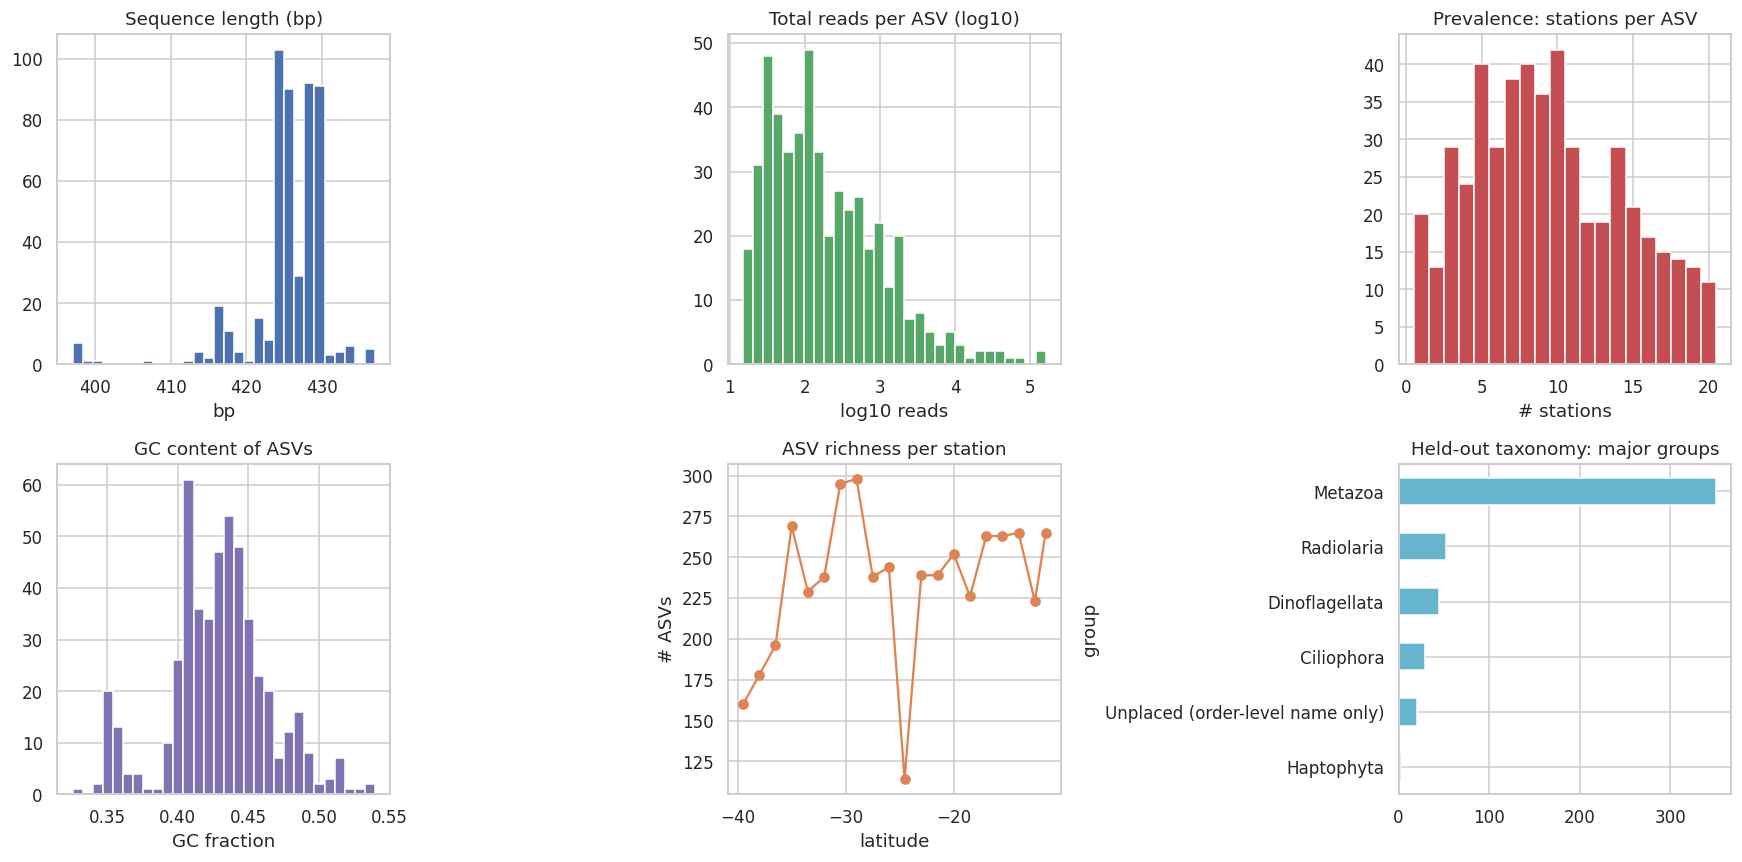

Reads per station: min 3685 | max 86010 | (uneven depth -> use relative abundance)


In [6]:
# ---- 2.7 Exploratory data analysis
fig, ax = plt.subplots(2, 3, figsize=(16, 8))
ax[0,0].hist(asv.length, bins=30, color='#4c72b0'); ax[0,0].set(title='Sequence length (bp)', xlabel='bp')
ax[0,1].hist(np.log10(asv.total_reads), bins=30, color='#55a868'); ax[0,1].set(title='Total reads per ASV (log10)', xlabel='log10 reads')
ax[0,2].hist(asv.n_stations, bins=np.arange(0.5, 21.5), color='#c44e52'); ax[0,2].set(title='Prevalence: stations per ASV', xlabel='# stations')
ax[1,0].hist(gc, bins=30, color='#8172b2'); ax[1,0].set(title='GC content of ASVs', xlabel='GC fraction')
rich = (A > 0).sum(axis=0)
ax[1,1].plot(stations.lat.values, rich.values, 'o-', color='#dd8452'); ax[1,1].set(title='ASV richness per station', xlabel='latitude', ylabel='# ASVs')
tax.group.value_counts().plot.barh(ax=ax[1,2], color='#64b5cd'); ax[1,2].set(title='Held-out taxonomy: major groups'); ax[1,2].invert_yaxis()
plt.tight_layout(); plt.show()
print('Reads per station: min', A.sum(axis=0).min(), '| max', A.sum(axis=0).max(), '| (uneven depth -> use relative abundance)')

## 3. Distance and similarity metrics  *(Unit I – Euclidean, Manhattan, Cosine; Practical 1)*
Does the choice of distance change which sequences look "close"? We compare the three metrics on the k-mer vectors (raw and standardised) and, **after the fact**, check how often an ASV's nearest neighbour shares its taxonomic class.

,features,metric,mean dist,1-NN same class (post-hoc)
0,raw k-mer freq,euclidean,0.0494,0.973
1,raw k-mer freq,manhattan,0.5541,0.975
2,raw k-mer freq,cosine,0.1798,0.973
3,standardised,euclidean,22.1992,0.973
4,standardised,manhattan,256.0633,0.975
5,standardised,cosine,0.9977,0.981


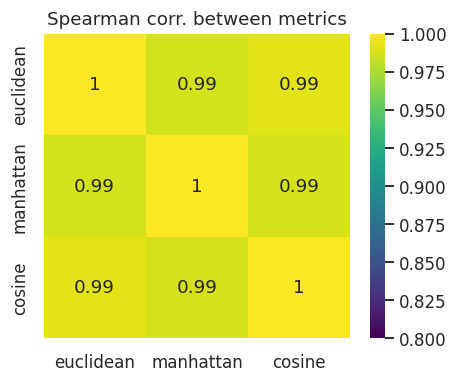

In [7]:
def nn_agreement(Dm, labels, mask):
    Dm = Dm.copy(); np.fill_diagonal(Dm, np.inf)
    nn = Dm.argmin(1)
    return float((labels[nn] == labels)[mask].mean())

rows, DM = [], {}
for fname, F in [('raw k-mer freq', Xk), ('standardised', Xs)]:
    for metric in ['euclidean', 'manhattan', 'cosine']:
        Dm = pairwise_distances(F, metric=metric); DM[(fname, metric)] = Dm
        rows.append({'features': fname, 'metric': metric,
                     'mean dist': Dm[np.triu_indices_from(Dm, 1)].mean().round(4),
                     '1-NN same class (post-hoc)': round(nn_agreement(Dm, y_cls, EVAL_MASK), 3)})
res_metric = pd.DataFrame(rows); display(res_metric)

iu = np.triu_indices(len(Xk), 1)
corr = pd.DataFrame({m: DM[('raw k-mer freq', m)][iu] for m in ['euclidean', 'manhattan', 'cosine']}).corr(method='spearman')
plt.figure(figsize=(4.5, 3.6)); sns.heatmap(corr, annot=True, cmap='viridis', vmin=0.8, vmax=1); plt.title('Spearman corr. between metrics'); plt.show()

**Reading the result.** Euclidean and Manhattan rank pairs almost identically on normalised k-mer frequencies; cosine focuses on the *shape* of the k-mer profile rather than its magnitude. Standardising changes which k-mers dominate the distance, which is why the choice of metric **and** scaling both matter for sequence data.

## 4. Partition-based clustering  *(Unit II; Practicals 2–5)*

### 4.1 Effect of feature scaling  *(Practical 4)*

In [8]:
def ext_scores(labels, mask=None):
    mask = EVAL_MASK if mask is None else mask & EVAL_MASK
    return {'ARI(class)': round(adjusted_rand_score(y_cls[mask], labels[mask]), 3),
            'NMI(class)': round(normalized_mutual_info_score(y_cls[mask], labels[mask]), 3),
            'ARI(group)': round(adjusted_rand_score(y_grp[mask], labels[mask]), 3),
            'Homog(class)': round(homogeneity_score(y_cls[mask], labels[mask]), 3),
            'Homog(group)': round(homogeneity_score(y_grp[mask], labels[mask]), 3)}

rows = []
spaces = {'raw k-mer freq': Xk, 'standardised k-mer': Xs, 'standardised + PCA20 (Z)': Z}
parts = {}
for name, F in spaces.items():
    km = KMeans(6, n_init=10, random_state=SEED).fit(F); parts[name] = km.labels_
    rows.append({'feature space': name, 'iterations to converge': km.n_iter_,
                 'silhouette': round(silhouette_score(F, km.labels_), 3),
                 'Davies-Bouldin': round(davies_bouldin_score(F, km.labels_), 3), **ext_scores(km.labels_)})
display(pd.DataFrame(rows))
print('ARI between raw and standardised partitions:', round(adjusted_rand_score(parts['raw k-mer freq'], parts['standardised k-mer']), 3))

,feature space,iterations to converge,silhouette,Davies-Bouldin,ARI(class),NMI(class),ARI(group),Homog(class),Homog(group)
0,raw k-mer freq,7,0.193,1.920,0.492,0.694,0.333,0.711,0.822
1,standardised k-mer,4,0.142,2.118,0.288,0.622,0.287,0.648,0.815
2,standardised + PCA20 (Z),6,0.262,1.556,0.284,0.621,0.288,0.645,0.814


ARI between raw and standardised partitions: 0.644


*Reading the table:* scaling changes the partition (see the ARI between raw and standardised runs). Standardising gives every one of the 256 k-mers equal weight, including very rare ones that are mostly noise, so raw frequencies and the PCA-compressed space behave differently. Because ARI against a coarse label such as "class" penalises clusters that **split** a class into finer groups, we also report **homogeneity** (does each cluster contain a single class?), which is the fairer post-hoc check for a clustering that is finer than the labels.

### 4.2 k-Means from scratch vs scikit-learn  *(Practical 3; initialisation strategies, convergence)*

                           scratch k-means++  scratch random  scikit-learn
best inertia                       46836.337       45695.361     45674.543
iterations (best run)                  6.000          14.000         6.000
mean iterations (10 runs)              6.900          10.400           NaN

ARI scratch(k-means++) vs sklearn: 0.689
Inertia spread over 10 inits  | k-means++: 46836.3-51285.9   random: 45695.4-57363.7


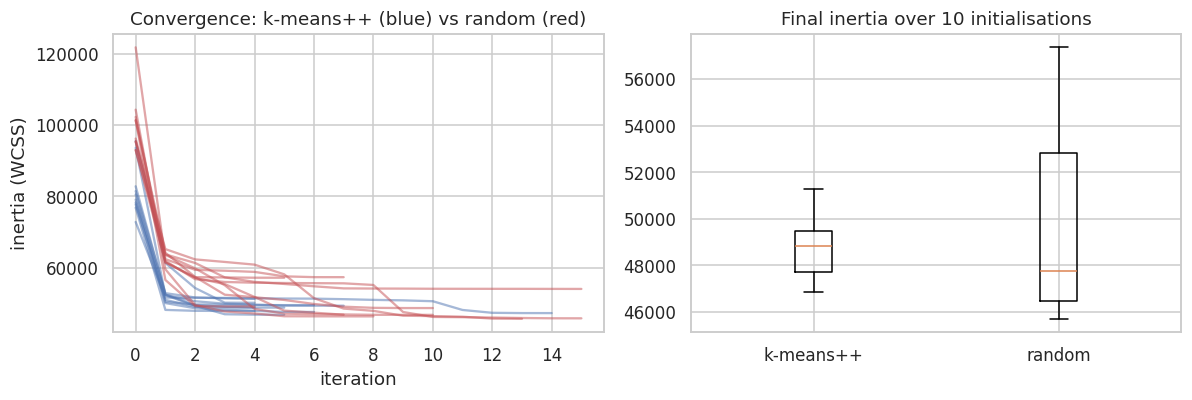

In [9]:
from scipy.spatial.distance import cdist
class KMeansScratch:
    # Lloyd's algorithm with random or k-means++ initialisation.
    def __init__(self, k, init='kmeans++', max_iter=300, tol=1e-6, seed=0):
        self.k, self.init, self.max_iter, self.tol, self.seed = k, init, max_iter, tol, seed
    def _init_centers(self, X, rng):
        n = len(X)
        if self.init == 'random':
            return X[rng.choice(n, self.k, replace=False)].copy()
        C = [X[rng.integers(n)]]
        for _ in range(1, self.k):
            d2 = cdist(X, np.array(C), 'sqeuclidean').min(1)
            C.append(X[rng.choice(n, p=d2 / d2.sum())])
        return np.array(C)
    def fit(self, X):
        rng = np.random.default_rng(self.seed)
        C = self._init_centers(X, rng); self.history = []
        for it in range(self.max_iter):
            d2 = cdist(X, C, 'sqeuclidean'); lab = d2.argmin(1)
            self.history.append(d2[np.arange(len(X)), lab].sum())
            newC = np.array([X[lab == j].mean(0) if (lab == j).any() else C[j] for j in range(self.k)])
            shift = np.linalg.norm(newC - C); C = newC
            if shift < self.tol: break
        self.centers_, self.labels_, self.n_iter_ = C, lab, it + 1
        self.inertia_ = ((X - C[lab]) ** 2).sum()
        return self

def best_of(init, k, X, n=10):
    runs = [KMeansScratch(k, init, seed=s).fit(X) for s in range(n)]
    return min(runs, key=lambda m: m.inertia_), runs

K_DEMO = 6
sc_pp, runs_pp = best_of('kmeans++', K_DEMO, Z)
sc_rd, runs_rd = best_of('random', K_DEMO, Z)
sk = KMeans(K_DEMO, n_init=10, random_state=SEED).fit(Z)
print(pd.DataFrame({'scratch k-means++': [sc_pp.inertia_, sc_pp.n_iter_, np.mean([r.n_iter_ for r in runs_pp])],
                    'scratch random':    [sc_rd.inertia_, sc_rd.n_iter_, np.mean([r.n_iter_ for r in runs_rd])],
                    'scikit-learn':      [sk.inertia_, sk.n_iter_, np.nan]},
                   index=['best inertia', 'iterations (best run)', 'mean iterations (10 runs)']).round(3).to_string())
print('\nARI scratch(k-means++) vs sklearn:', round(adjusted_rand_score(sc_pp.labels_, sk.labels_), 3))
print('Inertia spread over 10 inits  | k-means++: %.1f-%.1f   random: %.1f-%.1f' % (
      min(r.inertia_ for r in runs_pp), max(r.inertia_ for r in runs_pp), min(r.inertia_ for r in runs_rd), max(r.inertia_ for r in runs_rd)))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for r in runs_pp: ax[0].plot(r.history, color='#4c72b0', alpha=.5)
for r in runs_rd: ax[0].plot(r.history, color='#c44e52', alpha=.5)
ax[0].set(title='Convergence: k-means++ (blue) vs random (red)', xlabel='iteration', ylabel='inertia (WCSS)')
ax[1].boxplot([[r.inertia_ for r in runs_pp], [r.inertia_ for r in runs_rd]], tick_labels=['k-means++', 'random']); ax[1].set(title='Final inertia over 10 initialisations')
plt.tight_layout(); plt.show()

### 4.3 k-Medoids (PAM-style) vs k-Means and MiniBatch k-Means  *(Practical 2; scalability)*

In [10]:
def kmedoids(Dm, k, max_iter=100):
    # PAM-style: greedy BUILD initialisation + alternating swap (Voronoi iteration) on a precomputed distance matrix.
    n = len(Dm); med = [int(Dm.sum(1).argmin())]
    while len(med) < k:
        best, bc = None, np.inf
        for c in range(n):
            if c in med: continue
            cost = np.minimum(Dm[:, med].min(1), Dm[:, c]).sum()
            if cost < bc: best, bc = c, cost
        med.append(best)
    med = np.array(med)
    for _ in range(max_iter):
        lab = Dm[:, med].argmin(1); new = med.copy()
        for j in range(k):
            idx = np.where(lab == j)[0]
            if len(idx): new[j] = idx[Dm[np.ix_(idx, idx)].sum(1).argmin()]
        if (new == med).all(): break
        med = new
    lab = Dm[:, med].argmin(1)
    return lab, med, Dm[np.arange(n), med[lab]].sum()

D_euc, D_man = pairwise_distances(Z), pairwise_distances(Z, metric='manhattan')
t = time.time(); lab_med_e, med_e, cost_e = kmedoids(D_euc, K_DEMO); t_med = time.time() - t
lab_med_m, med_m, cost_m = kmedoids(D_man, K_DEMO)
t = time.time(); km_full = KMeans(K_DEMO, n_init=10, random_state=SEED).fit(Z); t_km = time.time() - t
t = time.time(); mb = MiniBatchKMeans(K_DEMO, n_init=10, batch_size=128, random_state=SEED).fit(Z); t_mb = time.time() - t

rows = []
for name, lab, Dm in [('k-Means', km_full.labels_, D_euc), ('MiniBatch k-Means', mb.labels_, D_euc),
                      ('k-Medoids (Euclid)', lab_med_e, D_euc), ('k-Medoids (Manhattan)', lab_med_m, D_man)]:
    rows.append({'method': name, 'silhouette (Euclid)': round(silhouette_score(Z, lab), 3), 'DB': round(davies_bouldin_score(Z, lab), 3),
                 'ARI vs k-Means': round(adjusted_rand_score(km_full.labels_, lab), 3), **ext_scores(lab)})
display(pd.DataFrame(rows))
print(f'Runtime  k-Means {t_km*1000:.0f} ms | MiniBatch {t_mb*1000:.0f} ms | k-Medoids {t_med*1000:.0f} ms (O(n^2) distance matrix)')
print('k-Medoids returns REAL sequences as cluster centres -> medoid ASVs:', list(asv.index[med_e]))

,method,silhouette (Euclid),DB,ARI vs k-Means,ARI(class),NMI(class),ARI(group),Homog(class),Homog(group)
0,k-Means,0.262,1.556,1.000,0.284,0.621,0.288,0.645,0.814
1,MiniBatch k-Means,0.266,1.574,0.762,0.261,0.574,0.176,0.613,0.682
2,k-Medoids (Euclid),0.220,1.678,0.600,0.197,0.518,0.203,0.545,0.677
3,k-Medoids (Manhattan),0.183,2.043,0.353,0.116,0.383,0.064,0.404,0.424


Runtime  k-Means 19 ms | MiniBatch 16 ms | k-Medoids 41 ms (O(n^2) distance matrix)
k-Medoids returns REAL sequences as cluster centres -> medoid ASVs: ['ASV_022', 'ASV_102', 'ASV_275', 'ASV_028', 'ASV_055', 'ASV_001']


*Takeaways:* k-means++ converges in fewer iterations and is much less variable from run to run than random starts (compare the inertia spread), and the best-of-10 solutions of all three implementations are within a few percent of each other. An ARI well below 1 between them shows that several near-equivalent local optima exist, which is typical when clusters are not sharply separated. k-Medoids is slower and quadratic in memory, but its centres are **actual ASVs**, which is valuable for interpretation (a medoid can be BLASTed or inspected). MiniBatch trades a little accuracy for speed, which matters when this pipeline is scaled to millions of reads.

### 4.4 Choosing the number of clusters  *(Practical 5; Elbow, Silhouette, Davies–Bouldin, elbow pitfalls)*

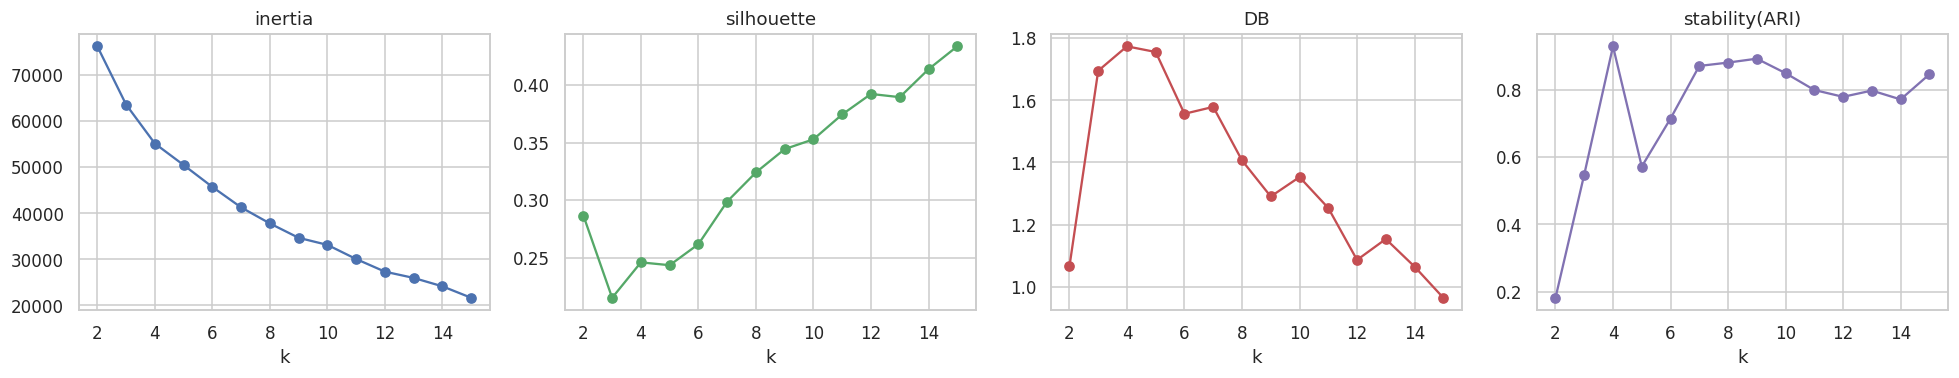

,inertia,silhouette,DB,CH,stability(ARI)
k,,,,,
2,76164.854,0.287,1.065,86.174,0.182
3,63538.270,0.215,1.695,100.730,0.548
4,55092.542,0.246,1.773,102.535,0.928
5,50428.929,0.243,1.755,95.241,0.572
6,45674.543,0.262,1.556,94.196,0.714
7,41239.595,0.299,1.578,95.562,0.870
8,37762.017,0.324,1.406,95.718,0.880
9,34643.505,0.344,1.290,96.608,0.892
10,33112.090,0.353,1.353,92.170,0.849


In [11]:
def subsample_stability(F, k, reps=8, frac=0.8, seed=0):
    rng = np.random.default_rng(seed); full = KMeans(k, n_init=5, random_state=SEED).fit(F).labels_; s = []
    for _ in range(reps):
        idx = rng.choice(len(F), int(frac * len(F)), replace=False)
        sub = KMeans(k, n_init=5, random_state=int(rng.integers(1e6))).fit(F[idx]).labels_
        s.append(adjusted_rand_score(full[idx], sub))
    return float(np.mean(s))

ks = list(range(2, 16)); rows = []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEED).fit(Z)
    rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(Z, km.labels_),
                 'DB': davies_bouldin_score(Z, km.labels_), 'CH': calinski_harabasz_score(Z, km.labels_),
                 'stability(ARI)': subsample_stability(Z, k)})
ksel = pd.DataFrame(rows).set_index('k')
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, (c, col) in zip(ax, [('inertia', '#4c72b0'), ('silhouette', '#55a868'), ('DB', '#c44e52'), ('stability(ARI)', '#8172b2')]):
    a.plot(ksel.index, ksel[c], 'o-', color=col); a.set(title=c, xlabel='k')
plt.tight_layout(); plt.show()
display(ksel.round(3))

In [12]:
# Transparent selection rule: among k = 3..12 pick the k with the best average RANK of
# silhouette (high), Davies-Bouldin (low) and stability (high). Ties -> smaller k.
cand = ksel.loc[3:12].copy()
cand['rank'] = (cand['silhouette'].rank(ascending=False) + cand['DB'].rank() + cand['stability(ARI)'].rank(ascending=False)) / 3
K_FINAL = int(cand['rank'].idxmin())
print('Rank table (lower is better):'); print(cand['rank'].round(2).to_string())
print('\n==> K_FINAL =', K_FINAL)

Rank table (lower is better):
k
3     9.33
4     6.33
5     9.00
6     7.00
7     5.67
8     4.33
9     3.00
10    4.00
11    3.33
12    3.00

==> K_FINAL = 9


**Elbow pitfalls.** The inertia curve decreases smoothly with no sharp elbow, which is common for biological data with groups of very different sizes (copepod-dominated metazoa vs. smaller protist groups). Inertia always falls as *k* grows, so we do not rely on it alone; silhouette, Davies–Bouldin and subsampling **stability** are combined in an explicit rule instead.

Cluster sizes: [ 10 103  84  59  72  44  31  80  15]
Silhouette: 0.344 | DB: 1.29 | CH: 96.6


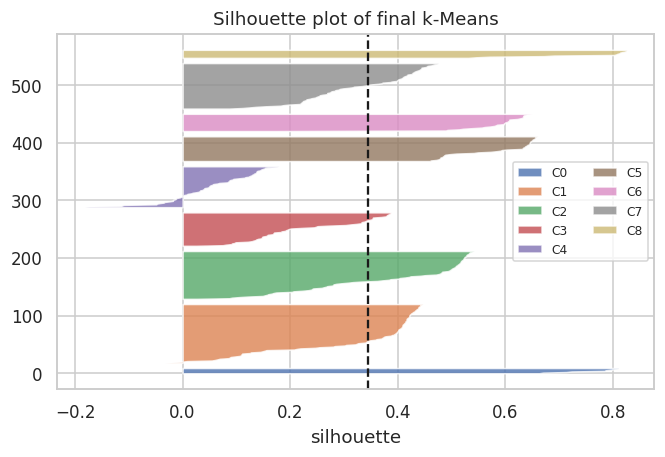

In [13]:
km_final = KMeans(K_FINAL, n_init=20, random_state=SEED).fit(Z)
labels_km = km_final.labels_
print('Cluster sizes:', np.bincount(labels_km))
print('Silhouette:', round(silhouette_score(Z, labels_km), 3), '| DB:', round(davies_bouldin_score(Z, labels_km), 3), '| CH:', round(calinski_harabasz_score(Z, labels_km), 1))
sil = silhouette_samples(Z, labels_km)
plt.figure(figsize=(7, 4.2)); y0 = 0
for c in range(K_FINAL):
    v = np.sort(sil[labels_km == c]); plt.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=.8, label=f'C{c}'); y0 += len(v) + 8
plt.axvline(sil.mean(), color='k', ls='--'); plt.title('Silhouette plot of final k-Means'); plt.xlabel('silhouette'); plt.legend(ncol=2, fontsize=8); plt.show()

## 5. Hierarchical, density-based and probabilistic clustering  *(Unit III; Practicals 6–8)*

### 5.1 Hierarchical clustering: linkage comparison and dendrograms  *(Practical 6)*

,linkage,cophenetic corr,largest cluster share,silhouette,DB,ARI(class),NMI(class),ARI(group),Homog(class),Homog(group)
0,single,0.862,0.83,0.190,0.849,0.254,0.433,0.398,0.309,0.437
1,complete,0.813,0.56,0.344,1.078,0.785,0.785,0.612,0.744,0.883
2,average,0.918,0.65,0.342,0.955,0.714,0.757,0.809,0.649,0.885
3,ward,0.687,0.22,0.343,1.342,0.337,0.698,0.235,0.804,0.962


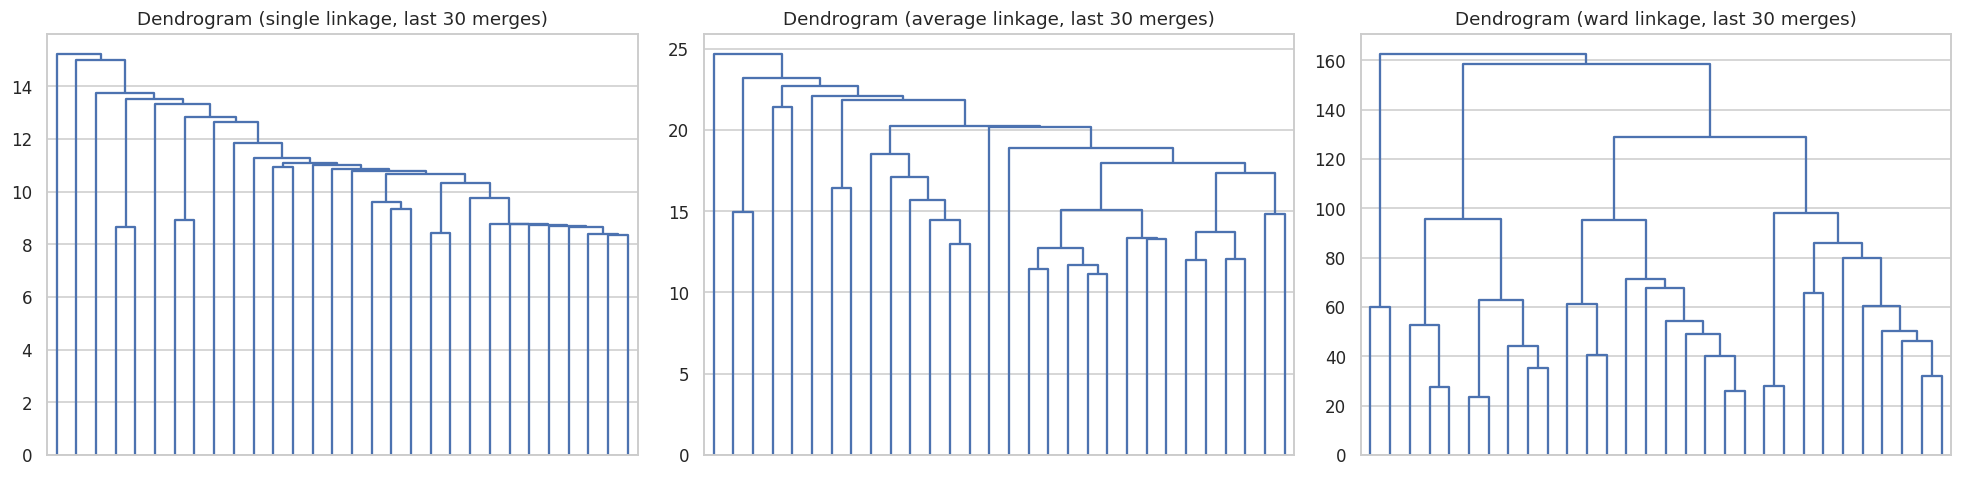

In [14]:
dZ = pdist(Z); rows = []; links = {}; lab_h = {}
for method in ['single', 'complete', 'average', 'ward']:
    L = linkage(Z, method); links[method] = L
    lab = fcluster(L, K_FINAL, 'maxclust') - 1; lab_h[method] = lab
    rows.append({'linkage': method, 'cophenetic corr': round(cophenet(L, dZ)[0], 3), 'largest cluster share': round(np.bincount(lab).max() / len(lab), 2),
                 'silhouette': round(silhouette_score(Z, lab), 3) if len(set(lab)) > 1 else np.nan,
                 'DB': round(davies_bouldin_score(Z, lab), 3), **ext_scores(lab)})
display(pd.DataFrame(rows))
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, m in zip(ax, ['single', 'average', 'ward']):
    dendrogram(links[m], truncate_mode='lastp', p=30, ax=a, no_labels=True, color_threshold=0); a.set_title(f'Dendrogram ({m} linkage, last 30 merges)')
plt.tight_layout(); plt.show()

Single linkage chains points into one giant cluster (see "largest cluster share"), a classic weakness. **Average** linkage best preserves the original pairwise distances (highest cophenetic correlation) and its top split lines up with the metazoan vs. protist divide, but it leaves a large dominant cluster. **Ward** produces the most balanced groups, which is what you want for a cluster-per-taxon-group summary. No single linkage wins on every criterion, which is why the choice should follow the purpose of the analysis.

### 5.2 DBSCAN: ε and MinPts, noise detection  *(Practical 7)*

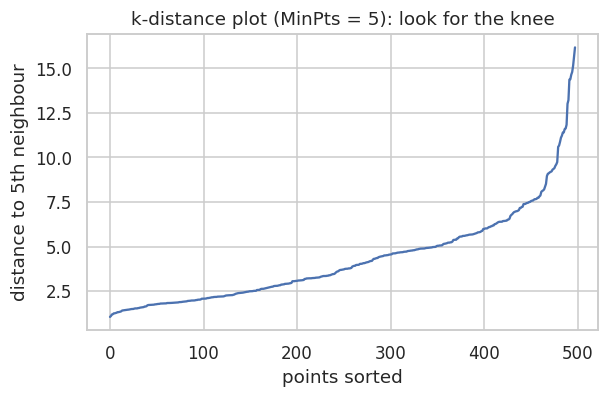

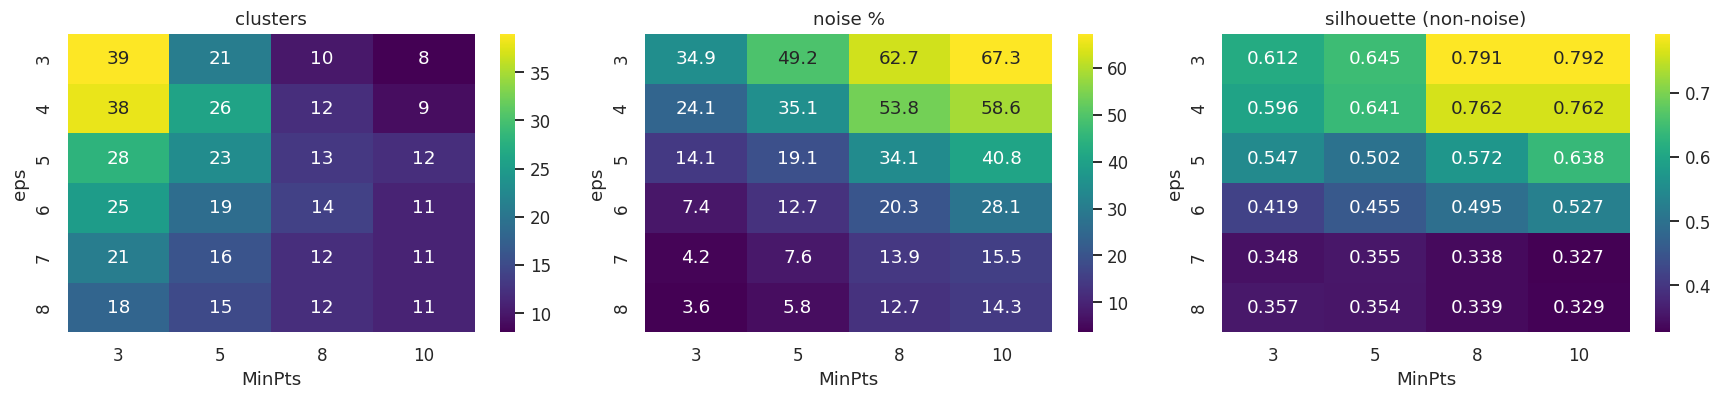

In [15]:
nn = NearestNeighbors(n_neighbors=6).fit(Z); kd = np.sort(nn.kneighbors(Z)[0][:, 5])
plt.figure(figsize=(6, 3.5)); plt.plot(kd); plt.title('k-distance plot (MinPts = 5): look for the knee'); plt.xlabel('points sorted'); plt.ylabel('distance to 5th neighbour'); plt.show()

eps_grid, ms_grid = [3, 4, 5, 6, 7, 8], [3, 5, 8, 10]; rows = []
for eps in eps_grid:
    for ms in ms_grid:
        lab = DBSCAN(eps=eps, min_samples=ms).fit(Z).labels_; core = lab != -1; nc = len(set(lab[core]))
        rows.append({'eps': eps, 'MinPts': ms, 'clusters': nc, 'noise %': round(100 * (~core).mean(), 1),
                     'silhouette (non-noise)': round(silhouette_score(Z[core], lab[core]), 3) if nc > 1 else np.nan})
grid = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a, c in zip(ax, ['clusters', 'noise %', 'silhouette (non-noise)']):
    sns.heatmap(grid.pivot(index='eps', columns='MinPts', values=c), annot=True, fmt='.3g', cmap='viridis', ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

In [16]:
# Selection rule: maximise silhouette on non-noise points, requiring 5-20 clusters and <= 25% noise
ok = grid[(grid.clusters.between(5, 20)) & (grid['noise %'] <= 25)].dropna()
best = ok.sort_values('silhouette (non-noise)', ascending=False).iloc[0]
EPS, MINPTS = float(best.eps), int(best.MinPts)
db = DBSCAN(eps=EPS, min_samples=MINPTS).fit(Z); labels_db = db.labels_
print(f'Chosen DBSCAN: eps={EPS}, MinPts={MINPTS} -> {len(set(labels_db)) - 1} clusters, {(labels_db == -1).sum()} noise points ({(labels_db == -1).mean():.1%})')
core_mask = np.zeros(len(Z), bool); core_mask[db.core_sample_indices_] = True
kind = np.where(labels_db == -1, 'noise', np.where(core_mask, 'core', 'border'))
print(pd.Series(kind).value_counts().to_string())

Chosen DBSCAN: eps=6.0, MinPts=8 -> 14 clusters, 101 noise points (20.3%)
core      341
noise     101
border     56


### 5.3 Soft clustering with a Gaussian Mixture  *(Unit II – hard vs soft; probabilistic methods)*

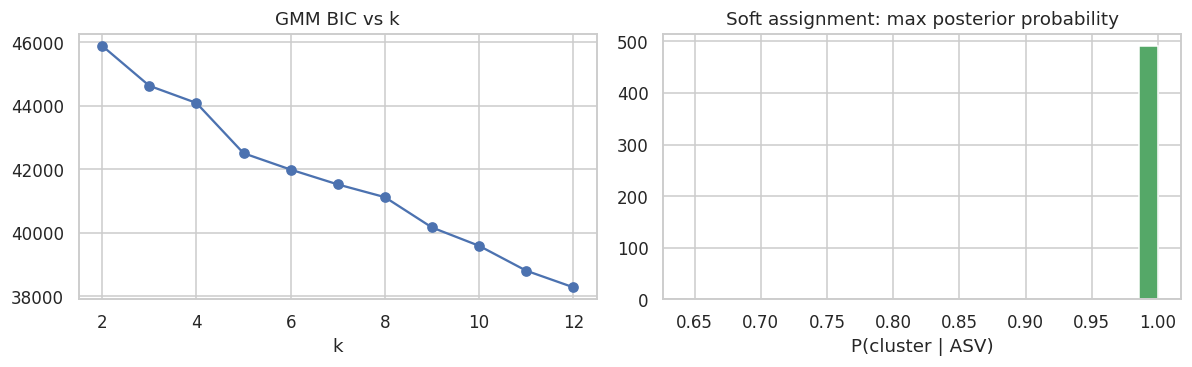

Ambiguous ASVs (max posterior < 0.8): 1 (0.2%) -> sequences that sit between taxon groups


In [17]:
bic = {k: GaussianMixture(k, covariance_type='diag', n_init=3, random_state=SEED).fit(Z).bic(Z) for k in range(2, 13)}
gmm = GaussianMixture(K_FINAL, covariance_type='diag', n_init=5, random_state=SEED).fit(Z)
post = gmm.predict_proba(Z); labels_gmm = post.argmax(1); conf = post.max(1)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(list(bic), list(bic.values()), 'o-'); ax[0].set(title='GMM BIC vs k', xlabel='k')
ax[1].hist(conf, bins=25, color='#55a868'); ax[1].set(title='Soft assignment: max posterior probability', xlabel='P(cluster | ASV)')
plt.tight_layout(); plt.show()
print(f'Ambiguous ASVs (max posterior < 0.8): {(conf < 0.8).sum()} ({(conf < 0.8).mean():.1%}) -> sequences that sit between taxon groups')

### 5.4 Benchmark: k-Means vs Hierarchical vs DBSCAN vs GMM  *(Practical 8; CO3, CO5)*

In [18]:
methods = {'k-Means': labels_km, 'k-Medoids': kmedoids(D_euc, K_FINAL)[0], 'Hierarchical (Ward)': lab_h['ward'],
           'Hierarchical (average)': lab_h['average'], 'GMM (soft->hard)': labels_gmm, 'DBSCAN': labels_db}
rows = []
for name, lab in methods.items():
    core = lab != -1; L = lab[core]; nc = len(set(L))
    rows.append({'method': name, 'clusters': nc, 'noise %': round(100 * (~core).mean(), 1),
                 'silhouette': round(silhouette_score(Z[core], L), 3) if nc > 1 else np.nan,
                 'DB': round(davies_bouldin_score(Z[core], L), 3) if nc > 1 else np.nan,
                 'CH': round(calinski_harabasz_score(Z[core], L), 1) if nc > 1 else np.nan, **ext_scores(lab, core)})
bench = pd.DataFrame(rows).set_index('method'); display(bench)

,clusters,noise %,silhouette,DB,CH,ARI(class),NMI(class),ARI(group),Homog(class),Homog(group)
method,,,,,,,,,,
k-Means,9,0.0,0.344,1.290,96.6,0.325,0.691,0.232,0.797,0.971
k-Medoids,9,0.0,0.323,1.418,88.0,0.243,0.624,0.181,0.738,0.893
Hierarchical (Ward),9,0.0,0.343,1.342,97.3,0.337,0.698,0.235,0.804,0.962
Hierarchical (average),9,0.0,0.342,0.955,51.0,0.714,0.757,0.809,0.649,0.885
GMM (soft->hard),9,0.0,0.317,1.392,90.8,0.273,0.652,0.204,0.770,0.931
DBSCAN,14,20.3,0.495,0.665,115.8,0.556,0.794,0.382,0.987,1.000


*Reading the benchmark:* internal metrics (silhouette, DB, CH) need no labels; the last three columns use the held-out taxonomy **only to evaluate**. DBSCAN reports metrics on non-noise points, so its numbers are not directly comparable: it gives up coverage to isolate noise.

## 6. Dimensionality reduction and representation learning  *(Unit IV; Practicals 9–10)*

### 6.1 PCA  *(geometric intuition, explained variance, interpretation)*

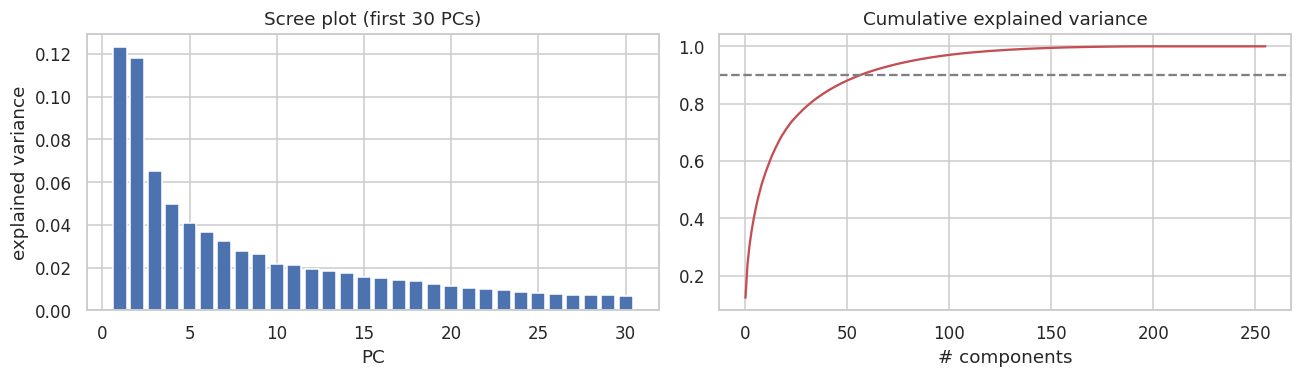

Components for 70% / 80% / 90% variance: [20, 33, 58]
Correlation of GC content with PC1/PC2: -0.15 / -0.88
Top k-mers loading on PC1  (+): ['GGTT', 'GTTT', 'GACA', 'AGGT', 'GTGC']  (-): ['GATA', 'CCTT', 'GCAC', 'CATC', 'TGGG']


In [19]:
pca_full = PCA(random_state=SEED).fit(Xs); ev = pca_full.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].bar(range(1, 31), ev[:30], color='#4c72b0'); ax[0].set(title='Scree plot (first 30 PCs)', xlabel='PC', ylabel='explained variance')
ax[1].plot(np.cumsum(ev), color='#c44e52'); ax[1].axhline(.9, ls='--', c='grey'); ax[1].set(title='Cumulative explained variance', xlabel='# components')
plt.tight_layout(); plt.show()
print('Components for 70% / 80% / 90% variance:', [int(np.searchsorted(np.cumsum(ev), q) + 1) for q in (.7, .8, .9)])
pca2 = pca_full.transform(Xs)[:, :2]
print('Correlation of GC content with PC1/PC2: %.2f / %.2f' % (np.corrcoef(gc, pca2[:, 0])[0, 1], np.corrcoef(gc, pca2[:, 1])[0, 1]))
load = pd.Series(pca_full.components_[0], index=kmer_names).sort_values()
print('Top k-mers loading on PC1  (+):', list(load.index[-5:][::-1]), ' (-):', list(load.index[:5]))

### 6.2 t-SNE and UMAP (conceptual non-linear methods) and a quantitative comparison

,trustworthiness@10,kNN same-class (post-hoc),runtime (s)
PCA,0.897,0.824,0.000
t-SNE,0.991,0.909,2.455
UMAP,0.979,0.890,16.963


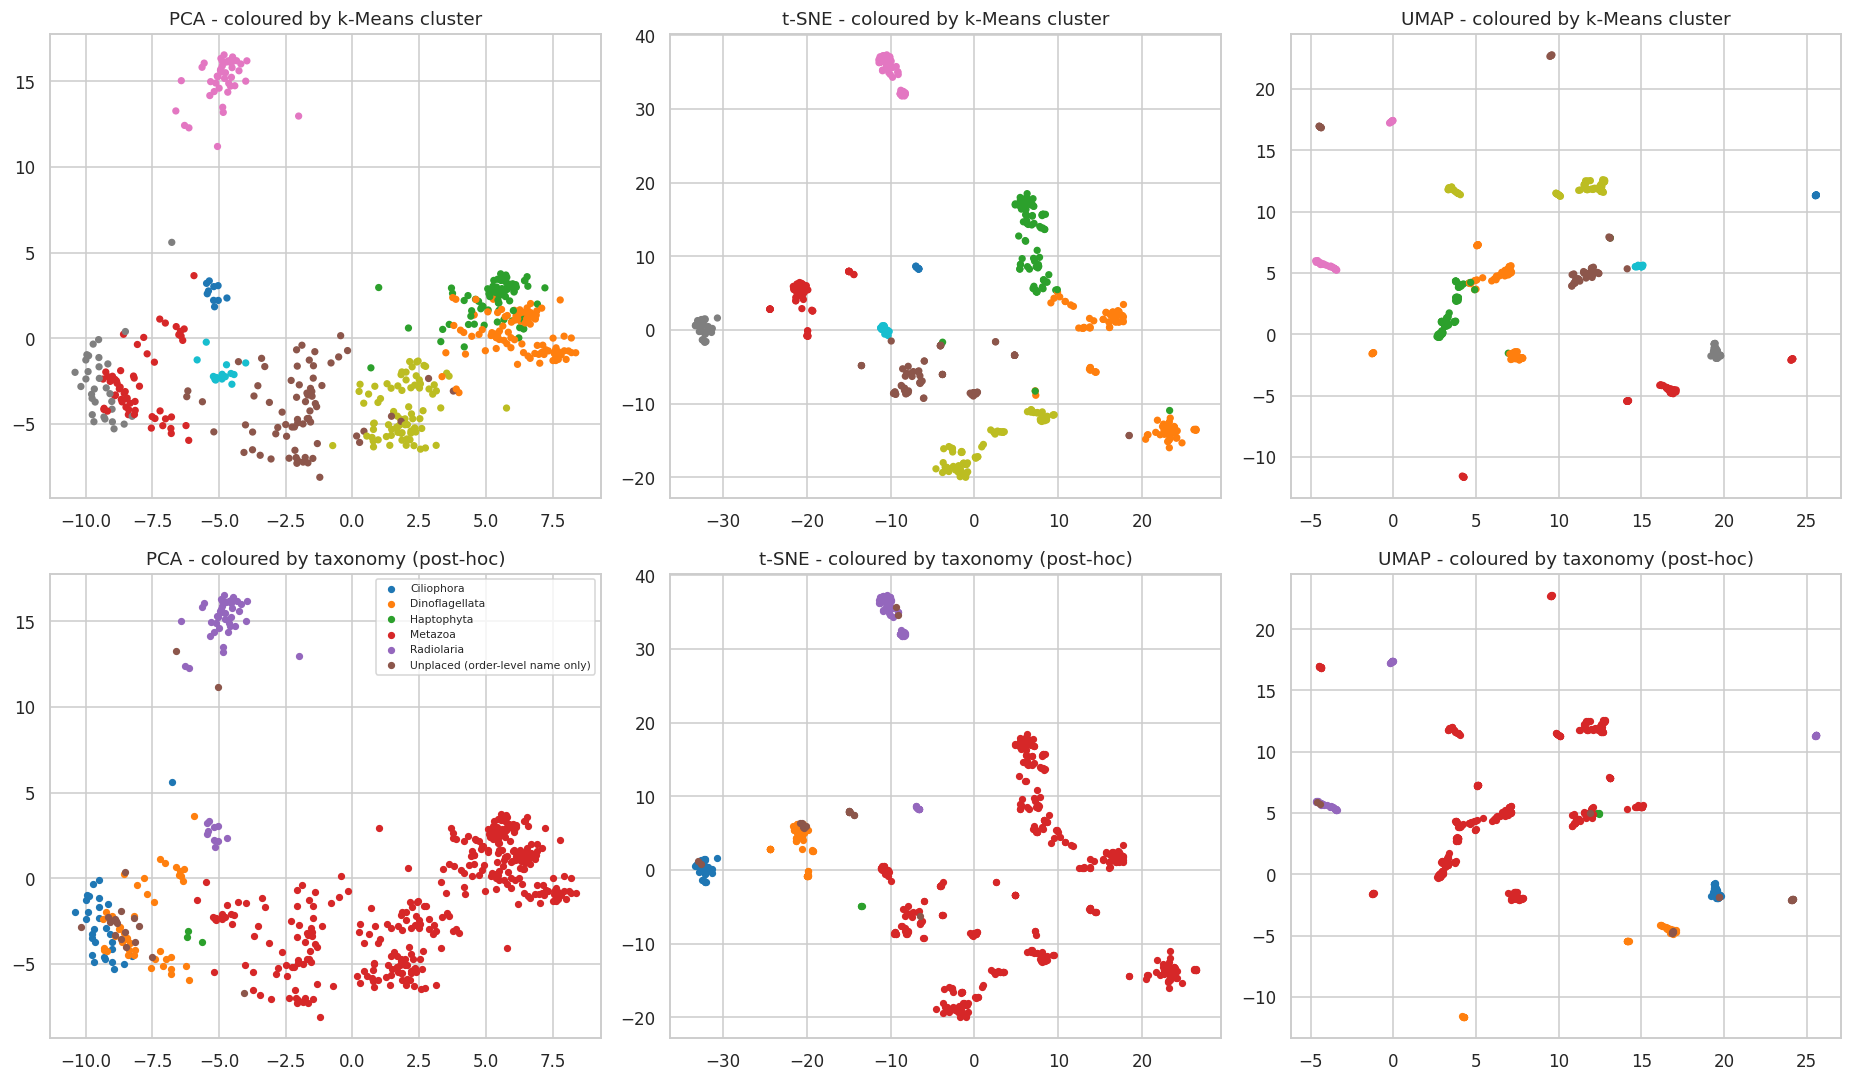

In [20]:
t = time.time(); tsne2 = TSNE(2, perplexity=30, init='pca', learning_rate='auto', random_state=SEED).fit_transform(Z); t_tsne = time.time() - t
t = time.time(); umap2 = umap.UMAP(n_neighbors=15, min_dist=0.1, random_state=SEED, n_jobs=1).fit_transform(Z); t_umap = time.time() - t
emb = {'PCA': pca2, 't-SNE': tsne2, 'UMAP': umap2}
trust = {n: trustworthiness(Z, E, n_neighbors=10) for n, E in emb.items()}
def knn_class_pres(E, k=10):
    idx = NearestNeighbors(n_neighbors=k + 1).fit(E).kneighbors(E)[1][:, 1:]
    return float(np.mean([(y_cls[idx[i]] == y_cls[i]).mean() for i in np.where(EVAL_MASK)[0]]))
cmp_dr = pd.DataFrame({'trustworthiness@10': trust, 'kNN same-class (post-hoc)': {n: knn_class_pres(E) for n, E in emb.items()},
                       'runtime (s)': {'PCA': 0.0, 't-SNE': t_tsne, 'UMAP': t_umap}}).round(3); display(cmp_dr)

palette = dict(zip(sorted(set(y_grp)), sns.color_palette('tab10', len(set(y_grp)))))
fig, ax = plt.subplots(2, 3, figsize=(17, 10))
for j, (n, E) in enumerate(emb.items()):
    ax[0, j].scatter(E[:, 0], E[:, 1], c=labels_km, cmap='tab10', s=14); ax[0, j].set_title(f'{n} - coloured by k-Means cluster')
    for g in palette: ax[1, j].scatter(E[y_grp == g, 0], E[y_grp == g, 1], s=14, color=palette[g], label=g)
    ax[1, j].set_title(f'{n} - coloured by taxonomy (post-hoc)')
ax[1, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

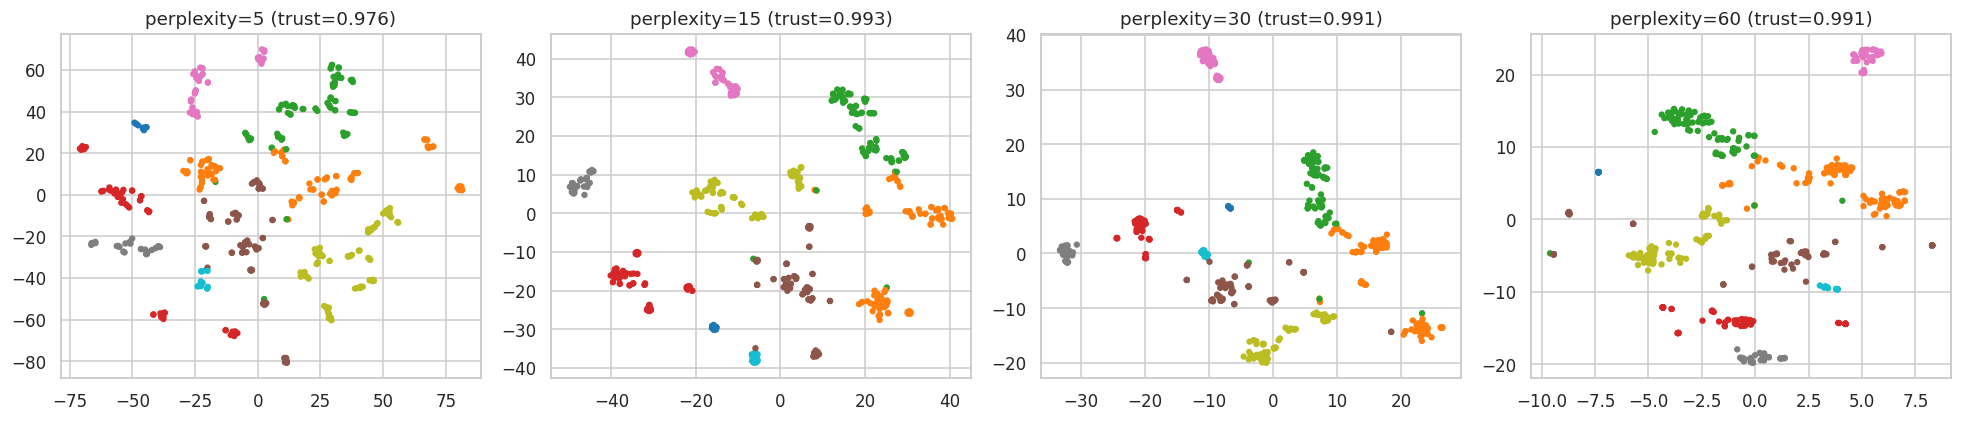

In [21]:
# t-SNE perplexity sensitivity
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, p in zip(ax, [5, 15, 30, 60]):
    E = TSNE(2, perplexity=p, init='pca', learning_rate='auto', random_state=SEED).fit_transform(Z)
    a.scatter(E[:, 0], E[:, 1], c=labels_km, cmap='tab10', s=10); a.set_title(f'perplexity={p} (trust={trustworthiness(Z, E, n_neighbors=10):.3f})')
plt.tight_layout(); plt.show()

### 6.3 Autoencoder intuition  *(a tiny bottleneck network compared with PCA)*

Reconstruction MSE through a 2-D bottleneck:  autoencoder = 1.577   PCA = 5.886


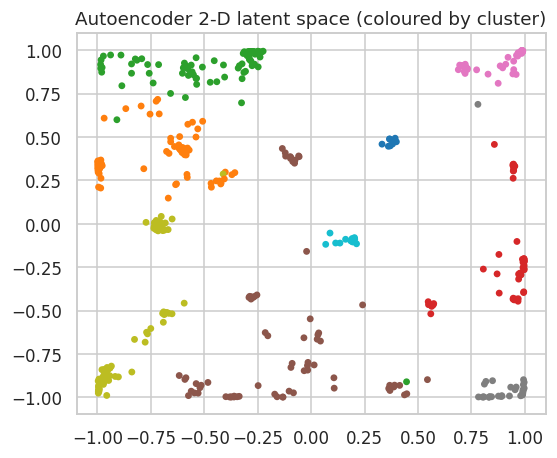

In [22]:
ae = MLPRegressor(hidden_layer_sizes=(32, 2, 32), activation='tanh', max_iter=3000, random_state=SEED, tol=1e-6).fit(Z, Z)
W, b = ae.coefs_, ae.intercepts_
latent = np.tanh(np.tanh(Z @ W[0] + b[0]) @ W[1] + b[1])        # 2-D bottleneck code
mse_ae = np.mean((ae.predict(Z) - Z) ** 2)
p2 = PCA(2).fit(Z); mse_pca = np.mean((p2.inverse_transform(p2.transform(Z)) - Z) ** 2)
print(f'Reconstruction MSE through a 2-D bottleneck:  autoencoder = {mse_ae:.3f}   PCA = {mse_pca:.3f}')
plt.figure(figsize=(5.5, 4.5)); plt.scatter(latent[:, 0], latent[:, 1], c=labels_km, cmap='tab10', s=12); plt.title('Autoencoder 2-D latent space (coloured by cluster)'); plt.show()

*Interpretation:* PCA is a linear projection with a closed form; t-SNE preserves **local** neighbourhoods (good for seeing groups, but distances between groups are not meaningful); UMAP keeps more global layout and is faster. An autoencoder learns a non-linear PCA-like code; with a tanh bottleneck it can reconstruct better than a 2-component PCA (training error shown here, so it also has more capacity to overfit), but on small data it is less stable and less interpretable.

## 7. Anomaly detection and association rules  *(Unit V; Practicals 11–12)*

### 7.1 Isolation Forest and Local Outlier Factor: candidate novel / undocumented taxa

In [23]:
CONT = 0.08
iso = IsolationForest(n_estimators=500, contamination=CONT, random_state=SEED).fit(Z)
iso_flag = iso.predict(Z) == -1;  iso_score = -iso.score_samples(Z)
lof = LocalOutlierFactor(n_neighbors=20, contamination=CONT).fit(Z)
lof_flag = lof.fit_predict(Z) == -1;  lof_score = -lof.negative_outlier_factor_
db_noise = labels_db == -1

print(f'Isolation Forest: {iso_flag.sum()} | LOF: {lof_flag.sum()} | DBSCAN noise: {db_noise.sum()}')
print(f'Overlap IF & LOF: {(iso_flag & lof_flag).sum()} | IF & DBSCAN: {(iso_flag & db_noise).sum()} | all three: {(iso_flag & lof_flag & db_noise).sum()}')
print('Rank correlation of anomaly scores (IF vs LOF): %.2f' % spearmanr(iso_score, lof_score)[0])

# consensus: Tier 1 = flagged by IF and LOF; Tier 2 = flagged by exactly one method AND DBSCAN noise
tier = np.where(iso_flag & lof_flag, 'Tier 1 (IF+LOF)', np.where((iso_flag | lof_flag) & db_noise, 'Tier 2 (one + DBSCAN)', 'typical'))
novel_flag = tier != 'typical'
print(pd.Series(tier).value_counts().to_string())

Isolation Forest: 40 | LOF: 40 | DBSCAN noise: 101
Overlap IF & LOF: 13 | IF & DBSCAN: 22 | all three: 7
Rank correlation of anomaly scores (IF vs LOF): 0.38
typical                  449
Tier 2 (one + DBSCAN)     36
Tier 1 (IF+LOF)           13


In [24]:
# POST-HOC interpretation with the held-out taxonomy
def enrichment(flag, label):
    a = int((flag & tax.poorly_resolved.values).sum()); b = int((flag & ~tax.poorly_resolved.values).sum())
    c = int((~flag & tax.poorly_resolved.values).sum()); d = int((~flag & ~tax.poorly_resolved.values).sum())
    OR, p = fisher_exact([[a, b], [c, d]])
    return {'flag set': label, 'n flagged': int(flag.sum()), 'poorly-resolved among flagged': f'{a / max(flag.sum(), 1):.0%}',
            'poorly-resolved overall': f'{tax.poorly_resolved.mean():.0%}', 'odds ratio': round(OR, 2), 'Fisher p': float(f'{p:.2g}')}
display(pd.DataFrame([enrichment(iso_flag, 'Isolation Forest'), enrichment(lof_flag, 'LOF'), enrichment(db_noise, 'DBSCAN noise'), enrichment(tier == 'Tier 1 (IF+LOF)', 'Tier 1 only (IF+LOF)'), enrichment(novel_flag, 'Consensus (Tier 1+2)')]))

# robustness filter: single-station / very low-read ASVs are often PCR or sequencing artefacts
asv['novel_tier'] = tier; asv['anomaly_IF'] = iso_score; asv['anomaly_LOF'] = lof_score
asv['robust'] = (asv.n_stations >= 3) & (asv.total_reads >= 50)
cand = (asv.join(tax[['group', 'cls', 'name', 'rank', 'poorly_resolved']]).loc[novel_flag]
        .sort_values(['novel_tier', 'anomaly_IF'], ascending=[True, False]))
print('\nConsensus candidates:', len(cand), '| robust (>=3 stations, >=50 reads):', int(cand.robust.sum()))
display(cand[cand.robust][['novel_tier', 'total_reads', 'n_stations', 'group', 'cls', 'name', 'rank', 'anomaly_IF', 'anomaly_LOF']].head(15).round(3))

,flag set,n flagged,poorly-resolved among flagged,poorly-resolved overall,odds ratio,Fisher p
0,Isolation Forest,40,62%,21%,7.88,2.800000e-09
1,LOF,40,20%,21%,0.93,1.000000e+00
2,DBSCAN noise,101,34%,21%,2.33,9.400000e-04
3,Tier 1 only (IF+LOF),13,46%,21%,3.34,3.600000e-02
4,Consensus (Tier 1+2),49,31%,21%,1.76,9.700000e-02



Consensus candidates: 49 | robust (>=3 stations, >=50 reads): 29


,novel_tier,total_reads,n_stations,group,cls,name,rank,anomaly_IF,anomaly_LOF
asv_id,,,,,,,,,
ASV_164,Tier 1 (IF+LOF),332,8,Metazoa,Arthropoda,"Acartia negligens Dana, 1849",species,0.556,1.857
ASV_284,Tier 1 (IF+LOF),102,9,Metazoa,Arthropoda,"Acartia negligens Dana, 1849",species,0.549,1.827
ASV_148,Tier 1 (IF+LOF),402,15,Metazoa,Arthropoda,"Acartia negligens Dana, 1849",species,0.548,2.061
ASV_351,Tier 1 (IF+LOF),58,12,Metazoa,Arthropoda,"Acartia negligens Dana, 1849",species,0.541,2.105
ASV_074,Tier 1 (IF+LOF),1156,9,Unplaced (order-level name only),Unplaced,"Spumellaria Ehrenberg, 1875",order,0.532,1.797
ASV_168,Tier 1 (IF+LOF),320,13,Unplaced (order-level name only),Unplaced,"Spumellaria Ehrenberg, 1875",order,0.531,1.789
ASV_203,Tier 1 (IF+LOF),200,6,Unplaced (order-level name only),Unplaced,"Spumellaria Ehrenberg, 1875",order,0.529,1.783
ASV_193,Tier 1 (IF+LOF),242,11,Metazoa,Arthropoda,"Acartia negligens Dana, 1849",species,0.528,1.863
ASV_211,Tier 1 (IF+LOF),181,12,Unplaced (order-level name only),Unplaced,"Spumellaria Ehrenberg, 1875",order,0.515,1.767


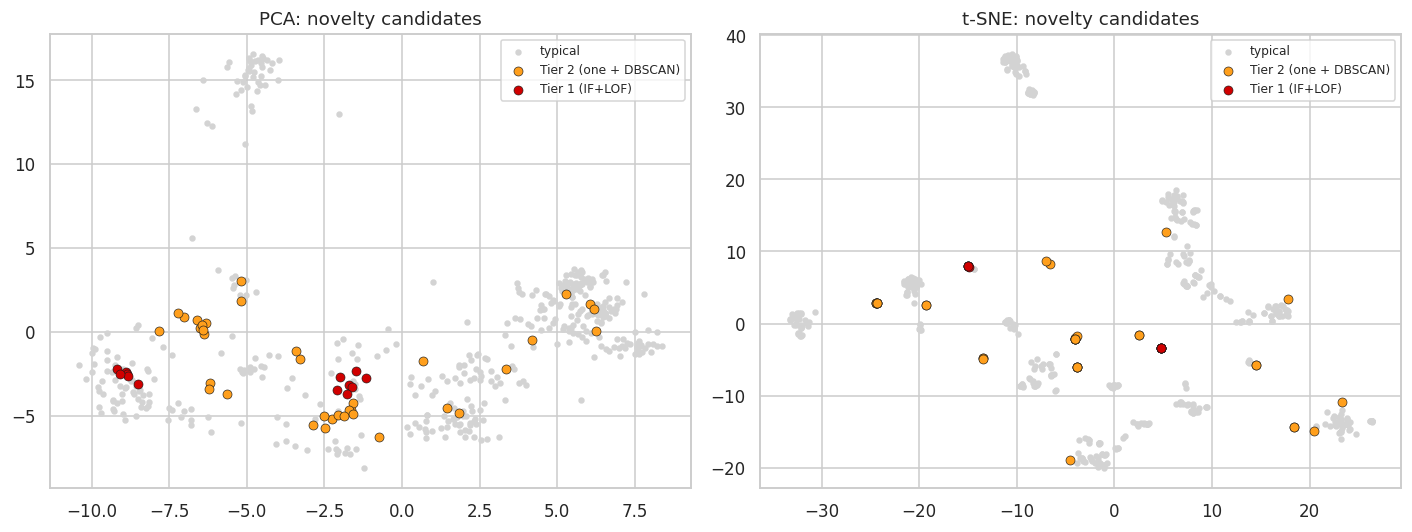

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (n, E) in zip(ax, [('PCA', pca2), ('t-SNE', tsne2)]):
    a.scatter(E[:, 0], E[:, 1], s=10, c='lightgrey', label='typical')
    for tname, col in [('Tier 2 (one + DBSCAN)', '#ff9f1c'), ('Tier 1 (IF+LOF)', '#d00000')]:
        m = tier == tname; a.scatter(E[m, 0], E[m, 1], s=35, c=col, label=tname, edgecolor='k', linewidth=.4)
    a.set_title(f'{n}: novelty candidates'); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**What the enrichment table shows.** Isolation Forest scores (global isolation in sequence space) are the ones most strongly linked to poorly resolved taxonomy, whereas LOF mostly flags *local* oddities inside dense groups such as copepods, which are not necessarily undocumented taxa. The consensus tiers are therefore useful as a shortlist, but the Isolation Forest score is the more informative ranking for novelty.

**Anomaly vs novelty detection.** Here we do *anomaly detection* on the observed data (a sequence that is unusual relative to the rest of the sample). Whether an anomaly is a truly *novel taxon* can only be confirmed with external evidence (BLAST/phylogenetic placement, a second marker, or morphology), so the output is a **ranked shortlist for follow-up**, not a claim of new species.

### 7.2 Association rule mining: which taxon-like clusters co-vary along the transect  *(Apriori, FP-Growth)*

In [26]:
# Market-basket analogy: basket = a sampling station; items = clusters that are ENRICHED at that station
# (share of the station's reads above the cluster's mean share) + a latitude zone.
df_c = pd.DataFrame({'cl': labels_km, 'asv_id': asv.index}).set_index('asv_id')
share = A.groupby(df_c.cl).sum().div(A.sum(axis=0), axis=1)            # cluster x station read share
enriched = share.gt(share.mean(axis=1), axis=0).T                     # station x cluster (bool)
enriched.columns = [f'C{c}_enriched' for c in enriched.columns]
zone = pd.cut(stations.set_index('station').lat, [-90, -30, -20, 0], labels=['Lat_south(<-30)', 'Lat_mid(-30..-20)', 'Lat_north(>-20)'])
basket = pd.concat([enriched, pd.get_dummies(zone).astype(bool)], axis=1).loc[stations.station].astype(bool)

t = time.time(); f_ap = apriori(basket, min_support=0.2, use_colnames=True); t_ap = time.time() - t
t = time.time(); f_fp = fpgrowth(basket, min_support=0.2, use_colnames=True); t_fp = time.time() - t
print(f'Frequent itemsets: Apriori {len(f_ap)} ({t_ap*1000:.1f} ms) | FP-Growth {len(f_fp)} ({t_fp*1000:.1f} ms) | identical: {set(map(frozenset, f_ap.itemsets)) == set(map(frozenset, f_fp.itemsets))}')
rules = association_rules(f_fp, num_itemsets=len(basket), metric='confidence', min_threshold=0.7)
rules = rules[(rules.lift > 1.1) & (rules.antecedents.apply(len) <= 2)]
rules = rules.sort_values(['lift', 'confidence'], ascending=False)
view = rules[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'conviction']].copy()
view['antecedents'] = view.antecedents.apply(lambda s: ' + '.join(sorted(s))); view['consequents'] = view.consequents.apply(lambda s: ' + '.join(sorted(s)))
display(view.head(12).round(3))

Frequent itemsets: Apriori 27 (3.8 ms) | FP-Growth 27 (2.7 ms) | identical: True


,antecedents,consequents,support,confidence,lift,conviction
10,C0_enriched + C3_enriched,Lat_south(<-30),0.20,1.000,2.857,inf
12,C0_enriched + C7_enriched,Lat_south(<-30),0.20,1.000,2.857,inf
16,C8_enriched,C4_enriched,0.20,1.000,2.500,inf
9,C3_enriched + Lat_south(<-30),C0_enriched,0.20,0.800,2.286,3.250
11,C7_enriched + Lat_south(<-30),C0_enriched,0.20,0.800,2.286,3.250
6,Lat_south(<-30),C0_enriched,0.25,0.714,2.041,2.275
7,C0_enriched,Lat_south(<-30),0.25,0.714,2.041,2.275
4,C7_enriched + Lat_south(<-30),C3_enriched,0.20,0.800,2.000,3.000
5,C3_enriched + Lat_south(<-30),C7_enriched,0.20,0.800,2.000,3.000
8,C0_enriched + Lat_south(<-30),C3_enriched,0.20,0.800,2.000,3.000


Rules such as *"latitude zone → cluster enriched"* describe **biogeographic structure**: which sequence-defined groups dominate which part of the transect. *Support* = fraction of stations containing the itemset, *confidence* = P(consequent | antecedent), *lift* > 1 = positive association, *conviction* = how much more often the rule would be wrong if antecedent and consequent were independent. With only 20 stations these rules are exploratory.

## 8. Evaluation, stability and interpretation  *(Unit VI; Practical 13; CO4, CO5)*

### 8.1 Stability of the clustering

In [27]:
rng = np.random.default_rng(SEED)
# (a) subsampling stability, (b) seed stability, (c) robustness to the k-mer length used for features
boot = []
for _ in range(40):
    idx = rng.choice(len(Z), int(.8 * len(Z)), replace=False)
    boot.append(adjusted_rand_score(labels_km[idx], KMeans(K_FINAL, n_init=5, random_state=int(rng.integers(1e6))).fit(Z[idx]).labels_))
seeds = [adjusted_rand_score(labels_km, KMeans(K_FINAL, n_init=1, random_state=s).fit(Z).labels_) for s in range(20)]
feat_rows = []
for kk in (3, 4, 5):
    Xa, _ = kmer_matrix(asv.DNA_sequence.values, kk); Za = PCA(20, random_state=SEED).fit_transform(StandardScaler().fit_transform(Xa))
    la = KMeans(K_FINAL, n_init=10, random_state=SEED).fit(Za).labels_
    feat_rows.append({'k-mer length': kk, 'ARI vs final': round(adjusted_rand_score(labels_km, la), 3), 'silhouette': round(silhouette_score(Za, la), 3), **ext_scores(la)})
print(f'Subsample stability (ARI, 40 x 80%): mean {np.mean(boot):.3f}, sd {np.std(boot):.3f}')
print(f'Seed stability (single-init ARI vs final, 20 seeds): mean {np.mean(seeds):.3f}')
display(pd.DataFrame(feat_rows))

# secondary view: do abundance profiles alone (no sequences) recover the same structure?
Ze = PCA(10, random_state=SEED).fit_transform(StandardScaler().fit_transform(X_eco))
le = KMeans(K_FINAL, n_init=10, random_state=SEED).fit(Ze).labels_
print('\nSample/abundance-feature view: silhouette %.3f | ARI vs sequence-based clusters %.3f | %s' % (silhouette_score(Ze, le), adjusted_rand_score(labels_km, le), ext_scores(le)))

Subsample stability (ARI, 40 x 80%): mean 0.875, sd 0.063
Seed stability (single-init ARI vs final, 20 seeds): mean 0.832


,k-mer length,ARI vs final,silhouette,ARI(class),NMI(class),ARI(group),Homog(class),Homog(group)
0,3,0.664,0.250,0.294,0.635,0.188,0.751,0.859
1,4,1.000,0.344,0.325,0.691,0.232,0.797,0.971
2,5,0.847,0.373,0.322,0.677,0.214,0.777,0.889



Sample/abundance-feature view: silhouette 0.276 | ARI vs sequence-based clusters 0.028 | {'ARI(class)': -0.039, 'NMI(class)': 0.175, 'ARI(group)': -0.001, 'Homog(class)': 0.178, 'Homog(group)': 0.223}


*Reading 8.1:* the clustering is stable under subsampling and seeds, and reasonably robust to the k-mer length (k = 4 and 5 agree well; k = 3 is too coarse). In contrast, clustering ASVs by their **station abundance profile** does not reproduce the sequence-based groups (ARI near zero against both the sequence clusters and the taxonomy): ASVs from very different lineages share similar distribution patterns along the transect. Sequence composition is therefore the informative view for taxonomic structure, and the abundance view is better used for ecology (Section 8.3).

### 8.2 Interpreting the clusters with the held-out taxonomy

,size,top genera (post-hoc),dominant group,group purity,dominant class,class purity,representative ASV,poorly resolved %,mean GC,median stations,reads %
cluster,,,,,,,,,,,
C0,10,-,Radiolaria,1.00,Acantharea,1.00,ASV_433 (Acantharea),100,0.419,10,0.1
C1,103,"Clausocalanus (42), Cosmocalanus (9), Neocalan...",Metazoa,1.00,Arthropoda,1.00,ASV_160 (Maxillopoda),0,0.422,10,25.8
C2,84,"Calocalanus (58), Paracalanus (9), Acrocalanus...",Metazoa,1.00,Arthropoda,1.00,ASV_467 (Calocalanus),0,0.412,9,26.7
C3,59,"Tripos (7), Blastodinium (3), Phalachroma (2)",Dinoflagellata,0.75,Dinophyceae,0.44,ASV_313 (Goniodoma polyedricum (Pouchet)),63,0.451,10,1.0
C4,72,"Acartia (9), Meganyctiphanes (2), Aplysia (2)",Metazoa,0.94,Arthropoda,0.33,ASV_461 (Mollusca),53,0.473,8,3.0
C5,44,"Collozoum (37), Sphaerozoum (2), Disolenia (2)",Radiolaria,0.95,Polycystinea,0.95,ASV_161 (Collozoum inerme (J. Müller)),5,0.355,3,7.6
C6,31,"Amphorides (3), Steenstrupiella (3), Dictyocys...",Ciliophora,0.94,Spirotrichea,0.90,ASV_471 (Salpingella),10,0.439,7,0.4
C7,80,"Oithona (34), Corycaeus (9), Sapphirina (6)",Metazoa,1.00,Arthropoda,1.00,ASV_019 (Maxillopoda),0,0.442,10,33.1
C8,15,-,Metazoa,1.00,Cnidaria,1.00,ASV_264 (Cnidaria),100,0.428,8,2.3


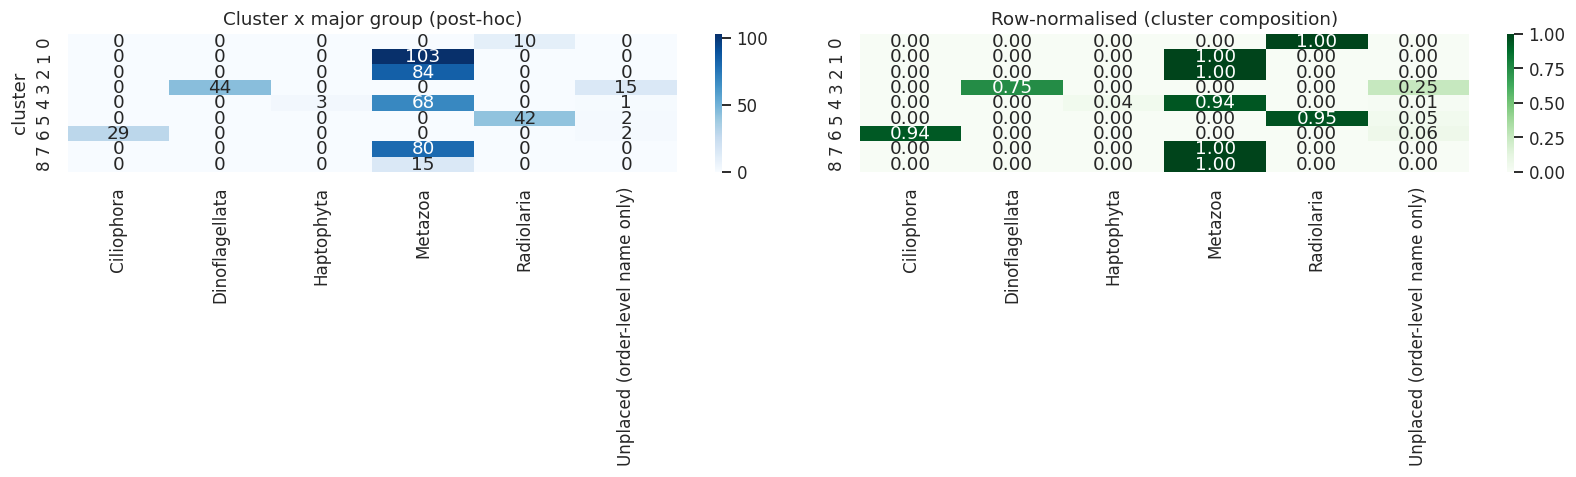

In [28]:
prof = pd.DataFrame({'cl': labels_km}, index=asv.index).join(tax).join(asv[['total_reads', 'n_stations']])
prof['gc'] = gc
rows = []
for c in range(K_FINAL):
    s = prof[prof.cl == c]; g = s.group.value_counts(); cl = s.cls.value_counts()
    ctr = np.linalg.norm(Z[labels_km == c] - km_final.cluster_centers_[c], axis=1); rep = s.index[ctr.argmin()]
    gen = s.genus.dropna().value_counts().head(3); topgen = ', '.join(f'{k_} ({v_})' for k_, v_ in gen.items()) or '-'
    rows.append({'cluster': f'C{c}', 'size': len(s), 'top genera (post-hoc)': topgen, 'dominant group': g.index[0], 'group purity': round(g.iloc[0] / len(s), 2),
                 'dominant class': cl.index[0], 'class purity': round(cl.iloc[0] / len(s), 2),
                 'representative ASV': f'{rep} ({prof.loc[rep, "name_clean"]})', 'poorly resolved %': round(100 * s.poorly_resolved.mean()),
                 'mean GC': round(s.gc.mean(), 3), 'median stations': int(s.n_stations.median()), 'reads %': round(100 * s.total_reads.sum() / prof.total_reads.sum(), 1)})
profile_table = pd.DataFrame(rows).set_index('cluster'); display(profile_table)

ct = pd.crosstab(prof.cl, prof.group)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', ax=ax[0]); ax[0].set(title='Cluster x major group (post-hoc)', xlabel='', ylabel='cluster')
sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=True, fmt='.2f', cmap='Greens', ax=ax[1]); ax[1].set(title='Row-normalised (cluster composition)', xlabel='', ylabel='')
plt.tight_layout(); plt.show()

### 8.3 Biodiversity assessment along the 110°E transect

station,S01,S02,S03,S04,S05,S06,S07,S08,S09,S10,S11,S12,S13,S14,S15,S16,S17,S18,S19,S20
lat,-39.49,-38.00,-36.50,-35.00,-33.50,-32.00,-30.50,-29.00,-27.50,-26.01,-24.56,-23.01,-21.50,-20.00,-18.51,-17.00,-15.50,-14.01,-12.50,-11.50
ASV richness,160.00,178.00,196.00,269.00,229.00,238.00,295.00,298.00,238.00,244.00,114.00,239.00,239.00,252.00,226.00,263.00,263.00,265.00,223.00,265.00
rarefied richness (3685 reads),84.15,95.75,103.00,139.70,150.05,110.55,165.60,174.55,136.65,134.35,104.05,117.90,129.30,137.25,118.00,143.90,139.50,156.35,121.40,117.85
Shannon (ASV),1.98,1.47,2.50,2.72,3.20,2.52,3.40,3.64,3.29,2.91,3.08,2.66,2.81,3.05,2.83,3.15,3.03,3.31,2.74,2.69
cluster richness,9.00,7.00,7.00,8.00,7.00,7.00,8.00,7.00,8.00,8.00,7.00,8.00,8.00,8.00,6.00,6.00,5.00,7.00,7.00,8.00
Shannon (cluster),1.09,0.70,1.03,1.25,1.23,0.96,1.22,1.27,1.45,1.35,1.49,1.28,1.08,1.50,1.10,1.20,1.18,1.31,1.27,1.27
reads,86010.00,73952.00,64720.00,53568.00,28745.00,56757.00,38651.00,46884.00,25840.00,30961.00,3685.00,47881.00,34641.00,48610.00,40111.00,38746.00,47841.00,45438.00,43638.00,80390.00


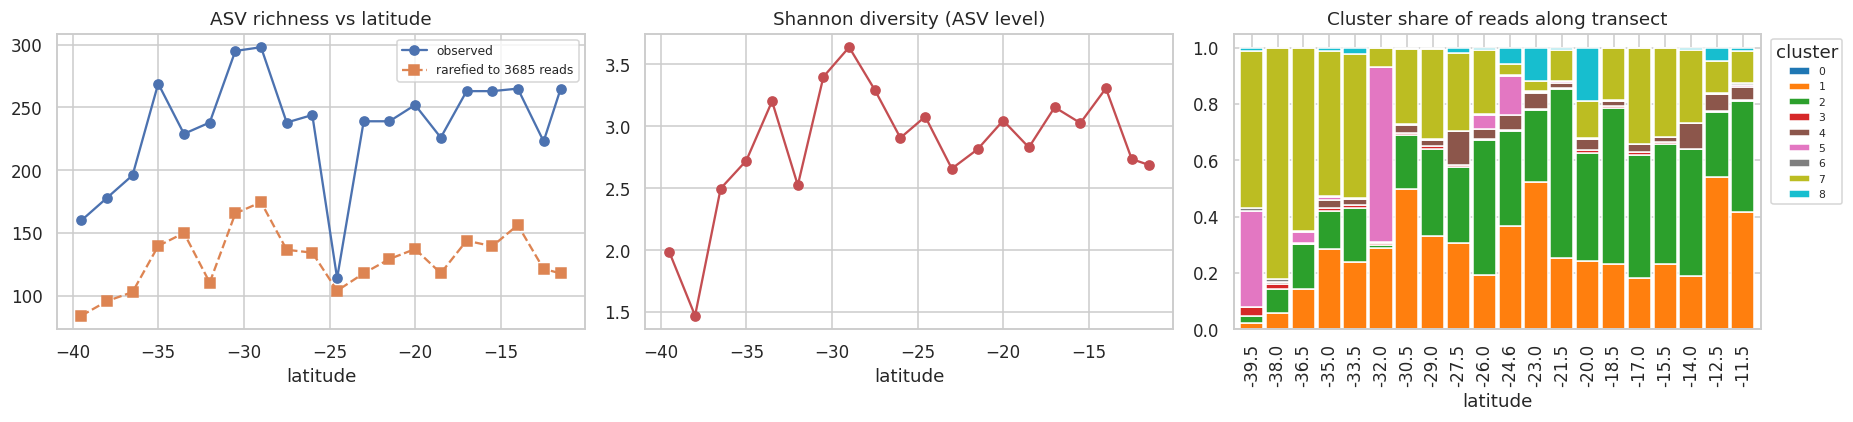

Spearman(ASV richness, latitude) = +0.31 (p = 0.178)
Spearman(rarefied richness (3685 reads), latitude) = +0.25 (p = 0.295)
Spearman(Shannon (ASV), latitude) = +0.30 (p = 0.200)
Spearman(Shannon (cluster), latitude) = +0.39 (p = 0.092)
Observed richness depends on sequencing depth; the rarefied row compares stations at equal depth.


In [29]:
def shannon(v):
    v = np.asarray(v, float); p = v[v > 0] / v.sum(); return float(-(p * np.log(p)).sum())
lat_s = stations.set_index('station').lat
# depth-standardised richness: rarefy every station to the same number of reads (the smallest library)
depth = int(A.sum(axis=0).min()); rg = np.random.default_rng(SEED)
def rarefy(counts, n):
    return int((rg.multinomial(n, counts / counts.sum()) > 0).sum())
rare = A.apply(lambda col: np.mean([rarefy(col.values.astype(float), depth) for _ in range(20)]), axis=0)
bio = pd.DataFrame({'lat': lat_s, 'ASV richness': (A > 0).sum(axis=0), f'rarefied richness ({depth} reads)': rare, 'Shannon (ASV)': A.apply(shannon),
                    'cluster richness': (share > 0.001).sum(axis=0), 'Shannon (cluster)': share.apply(shannon),
                    'reads': A.sum(axis=0)})
display(bio.round(2).T)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(bio.lat, bio['ASV richness'], 'o-', label='observed'); ax[0].plot(bio.lat, bio[f'rarefied richness ({depth} reads)'], 's--', label=f'rarefied to {depth} reads'); ax[0].legend(fontsize=8); ax[0].set(title='ASV richness vs latitude', xlabel='latitude')
ax[1].plot(bio.lat, bio['Shannon (ASV)'], 'o-', c='#c44e52'); ax[1].set(title='Shannon diversity (ASV level)', xlabel='latitude')
share.T.set_index(lat_s.round(1).values).plot.bar(stacked=True, ax=ax[2], colormap='tab10', width=.9); ax[2].set(title='Cluster share of reads along transect', xlabel='latitude'); ax[2].legend(title='cluster', fontsize=7, ncol=1, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()
for col in ['ASV richness', f'rarefied richness ({depth} reads)', 'Shannon (ASV)', 'Shannon (cluster)']:
    r, p = spearmanr(bio.lat, bio[col]); print(f'Spearman({col}, latitude) = {r:+.2f} (p = {p:.3f})')
print('Observed richness depends on sequencing depth; the rarefied row compares stations at equal depth.')

### 8.4 Interpretability challenges and ethical considerations *(Unit VI)*
* **No ground truth:** clusters are *sequence-similarity groups*, not species. 18S V4 has limited resolution for closely related species (e.g. many copepods), so one cluster can hold several species and one species can span clusters.
* **Reference bias:** the taxonomy used for interpretation comes from PR2 classification (RDP bootstrap ≥ 0.5). Poorly documented groups appear as "poorly resolved", and this partly reflects database gaps rather than biology.
* **Novelty claims need care:** anomaly flags can be caused by PCR/sequencing errors, chimeras, or low-read ASVs. We therefore report a *robust* subset (≥ 3 stations and ≥ 50 reads) and phrase results as candidates for follow-up (BLAST, phylogenetic placement, additional markers).
* **Read counts are not abundances:** PCR bias and uneven sequencing depth distort abundance-based diversity; we use relative abundance and flag the depth caveat.
* **Data ethics:** the data are public (OBIS, University of Auckland; see the citation printed in Section 1) and must be cited. Biodiversity outputs can influence conservation or fisheries decisions, so uncertainty must be communicated rather than hidden behind a single clustering.

## 9. End-to-end summary, dashboard and export  *(Case study + Project component; Practical 14)*

In [30]:
summary = {
    'ASVs analysed': len(asv), 'Stations': A.shape[1], 'Features': f'{K}-mer composition ({Xk.shape[1]}-d) -> PCA {Z.shape[1]}-d ({pca_cluster.explained_variance_ratio_.sum():.0%} var.)',
    'Final k (k-Means)': K_FINAL, 'Silhouette / DB': f'{silhouette_score(Z, labels_km):.3f} / {davies_bouldin_score(Z, labels_km):.3f}',
    'Stability (subsample ARI)': round(float(np.mean(boot)), 3),
    'Post-hoc ARI vs class / group': f"{ext_scores(labels_km)['ARI(class)']} / {ext_scores(labels_km)['ARI(group)']}",
    'DBSCAN': f'eps={EPS}, MinPts={MINPTS}, {(labels_db == -1).sum()} noise',
    'Novelty candidates (T1+T2 / robust)': f'{int(novel_flag.sum())} / {int((novel_flag & asv.robust.values).sum())}',
    'Trustworthiness PCA / t-SNE / UMAP': ' / '.join(f'{trust[n]:.3f}' for n in ['PCA', 't-SNE', 'UMAP'])}
for k_, v_ in summary.items(): print(f'{k_:<40}{v_}')

ASVs analysed                           498
Stations                                20
Features                                4-mer composition (256-d) -> PCA 20-d (70% var.)
Final k (k-Means)                       9
Silhouette / DB                         0.344 / 1.290
Stability (subsample ARI)               0.875
Post-hoc ARI vs class / group           0.325 / 0.232
DBSCAN                                  eps=6.0, MinPts=8, 101 noise
Novelty candidates (T1+T2 / robust)     49 / 29
Trustworthiness PCA / t-SNE / UMAP      0.897 / 0.991 / 0.979


In [31]:
# ---- Export results
res = (asv[['DNA_sequence', 'length', 'total_reads', 'n_stations', 'novel_tier', 'anomaly_IF', 'anomaly_LOF', 'robust']]
       .assign(cluster_kmeans=labels_km, cluster_ward=lab_h['ward'], cluster_dbscan=labels_db, gmm_confidence=conf.round(3),
               pca1=pca2[:, 0], pca2=pca2[:, 1], tsne1=tsne2[:, 0], tsne2=tsne2[:, 1], umap1=umap2[:, 0], umap2=umap2[:, 1])
       .join(tax[['group', 'cls', 'name', 'rank', 'poorly_resolved']]))
res.to_csv(f'{OUT_DIR}/asv_clusters.csv')
res[res.novel_tier != 'typical'].sort_values('anomaly_IF', ascending=False).to_csv(f'{OUT_DIR}/novelty_candidates.csv')
profile_table.to_csv(f'{OUT_DIR}/cluster_profiles.csv'); bio.to_csv(f'{OUT_DIR}/station_biodiversity.csv')
print('Saved: asv_clusters.csv, novelty_candidates.csv, cluster_profiles.csv, station_biodiversity.csv ->', os.path.abspath(OUT_DIR))

Saved: asv_clusters.csv, novelty_candidates.csv, cluster_profiles.csv, station_biodiversity.csv -> /home/claude/proj


### 9.1 Visualization dashboard: PCA vs t-SNE (vs UMAP)  *(syllabus project component)*

In [32]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

hover = [f'<b>{i}</b><br>{tax.loc[i, "name_clean"]} ({tax.loc[i, "rank"]})<br>group: {tax.loc[i, "group"]}<br>cluster: C{labels_km[n]} | reads: {int(asv.loc[i, "total_reads"])} | stations: {int(asv.loc[i, "n_stations"])}<br>novelty: {tier[n]}'
         for n, i in enumerate(asv.index)]
hover = np.array(hover)
colorings = {'k-Means cluster': np.array([f'C{c}' for c in labels_km]),
             'Taxonomy group (post-hoc)': y_grp.astype(str),
             'Novelty candidates': tier.astype(str)}
pal = sns.color_palette('tab10', 12).as_hex(); ncols = {'Novelty candidates': {'typical': '#cfcfcf', 'Tier 1 (IF+LOF)': '#d00000', 'Tier 2 (one + DBSCAN)': '#ff9f1c'}}

fig = make_subplots(rows=2, cols=3, specs=[[{}, {}, {}], [{}, {'colspan': 2}, None]], vertical_spacing=.14,
                    subplot_titles=[f'PCA (trustworthiness {trust["PCA"]:.2f})', f't-SNE (trustworthiness {trust["t-SNE"]:.2f})', f'UMAP (trustworthiness {trust["UMAP"]:.2f})',
                                    'Diversity along 110°E', 'Cluster share of reads by station (south to north)'])
meta = []
for cname, labs in colorings.items():
    cats = sorted(set(labs), key=lambda s: (s != 'typical', s))
    for col, (ename, E) in enumerate(emb.items(), 1):
        for ci, cat in enumerate(cats):
            m = labs == cat
            colr = ncols.get(cname, {}).get(cat, pal[ci % len(pal)])
            fig.add_trace(go.Scatter(x=E[m, 0], y=E[m, 1], mode='markers', name=str(cat), legendgroup=f'{cname}-{cat}', showlegend=(col == 1),
                          marker=dict(size=np.clip(np.log10(asv.total_reads.values[m] + 1) * 4, 4, 16), color=colr, line=dict(width=.4, color='#333'), opacity=.85),
                          text=hover[m], hoverinfo='text', visible=(cname == 'k-Means cluster')), row=1, col=col)
            meta.append(cname)
fig.add_trace(go.Scatter(x=bio.lat, y=bio['ASV richness'], name='ASV richness (observed)', mode='lines+markers', line=dict(color='#1f77b4')), row=2, col=1); meta.append('all')
fig.add_trace(go.Scatter(x=bio.lat, y=bio['Shannon (ASV)'] * 20, name='Shannon x20', mode='lines+markers', line=dict(color='#d62728')), row=2, col=1); meta.append('all')
for c in share.index:
    fig.add_trace(go.Bar(x=stations.lat.round(1).astype(str), y=share.loc[c], name=f'C{c} share', marker_color=pal[c % len(pal)], showlegend=False), row=2, col=2); meta.append('all')
fig.update_layout(barmode='stack', height=900, margin=dict(t=150), template='plotly_white', legend=dict(orientation='v', x=1.01, y=1),
                  title='eDNA 18S plankton (Indian Ocean, 110°E): sequence-based clusters, PCA vs t-SNE vs UMAP',
                  updatemenus=[dict(type='dropdown', x=0.0, y=1.14, xanchor='left', buttons=[
                      dict(label=f'Colour by: {c}', method='update', args=[{'visible': [(m == c) or (m == 'all') for m in meta]}]) for c in colorings])])
dash_path = f'{OUT_DIR}/edna_pca_tsne_dashboard.html'
fig.write_html(dash_path, include_plotlyjs=True); print('Dashboard saved:', os.path.abspath(dash_path))

Dashboard saved: /home/claude/proj/edna_pca_tsne_dashboard.html


## 10. Conclusions
1. **Sequence composition alone carries taxonomic signal:** k-mer clusters, built without names, are highly homogeneous with respect to the held-out PR2 taxonomy (radiolarians, ciliates, dinoflagellates and cnidarians each fall into their own clusters) and split the copepod-dominated metazoa into finer sub-groups. ARI against coarse labels is modest precisely because the clusters are finer than the labels.
2. **Method comparison:** k-Means/Ward give balanced groups; average linkage best preserves distances; DBSCAN isolates noise (candidate rare taxa); GMM quantifies ambiguity; PCA/UMAP/t-SNE trade global vs local fidelity (see the trustworthiness table). Abundance-profile features do *not* recover taxonomy, which justifies sequence-based features.
3. **Novelty shortlist:** Isolation Forest scores are strongly enriched for taxa the reference database resolves poorly, and the IF/LOF/DBSCAN consensus plus a robustness filter gives a ranked shortlist to follow up.
4. **Biodiversity:** richness (observed and depth-rarefied) rises from the southern end of the transect up to roughly 30°S and then stays on a plateau. A monotonic rank test against latitude is not significant with only 20 stations, so this is a descriptive pattern, and it is in line with the source study's title, which describes diversity stabilising across the oligotrophic region. Cluster composition shifts more visibly than richness (for example a radiolarian-dominated cluster peaks at a few southern stations).
5. **Limitations and future work:** 18S V4 resolution limits, no abundance calibration, only 20 stations; next steps include HDBSCAN, BLAST/phylogenetic validation of candidates, and adding the second marker or other cruise datasets.